# Seminar AI – Nhóm 10: XGBoost vs Random Forest
**Bài toán:** hồi quy dự đoán `rating_2026` của phim trong Top 250 IMDb.

## Mục lục
0. Cấu hình
1. Nạp dữ liệu và gộp 3 bảng (merge)
2. Phân tích khám phá dữ liệu (EDA)
3. Tiền xử lý và chia train/test
4. Huấn luyện mô hình (Random Forest và XGBoost, 300 cây mỗi mô hình)
5. **DEMO – 6 biểu đồ**
   - Biểu đồ 1: Cây Random Forest
   - Biểu đồ 2: Cây XGBoost
   - *Demo cơ chế XGBoost từng bước, có số liệu* (Phần A, B, C)
   - Biểu đồ 3: MAE – RMSE – R²
   - Biểu đồ 4: Thời gian huấn luyện
   - Biểu đồ 5: Actual vs Predicted
   - Biểu đồ 6: Feature Importance
6. Phụ lục (chỉ mở khi được hỏi)

## 0. Cấu hình

In [1]:
import os, re, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
N_TREES = 300

## 1. Nạp dữ liệu và gộp 3 bảng

Ba bộ dữ liệu Top 250 IMDb ở ba thời điểm khác nhau:

| Biến | Nguồn (Kaggle) | Ý nghĩa |
|---|---|---|
| `df1` | `ashishjangra27/imdb-top-250-movies` | danh sách cũ (hậu tố `_v1`) |
| `df5` | `rajugc/imdb-top-250-movies-dataset` | có `box_office`, `tagline` |
| `df6` | `arjunsinghgangwar/top-250-movies-on-imdb-in-2026` | danh sách 2026 (chứa `rating_2026`, là biến mục tiêu) |

In [2]:
import kagglehub

path1 = kagglehub.dataset_download("ashishjangra27/imdb-top-250-movies")
path5 = kagglehub.dataset_download("rajugc/imdb-top-250-movies-dataset")
path6 = kagglehub.dataset_download("arjunsinghgangwar/top-250-movies-on-imdb-in-2026")

df1 = pd.read_csv(os.path.join(path1, 'movies.csv')).drop(columns=['certificate'])
df5 = pd.read_csv(os.path.join(path5, 'IMDB Top 250 Movies.csv'))
df6 = pd.read_csv(os.path.join(path6, 'ToP 250 movies on imdb in 2026.csv')).drop(
    columns=['url', 'id', 'originalTitle', 'type', 'primaryImage', 'thumbnails', 'trailer'])

print('df1:', df1.shape, '| df5:', df5.shape, '| df6:', df6.shape)

df1: (250, 15) | df5: (250, 13) | df6: (250, 20)


### Chuẩn hóa khóa ghép và gộp (outer join)
Khóa ghép là `title_key` (tên phim viết thường, bỏ ký tự đặc biệt) cùng với `year`. Outer join giữ cả phim chỉ xuất hiện ở một bảng, nên số dòng sau gộp lớn hơn 250.

In [3]:
def create_title_key(series):
    return (series.astype(str).str.strip().str.lower()
            .str.replace(r"[^\w\s]", "", regex=True))

def parse_runtime_to_minutes(val):
    # '2h 22m' -> 142
    if pd.isna(val):
        return np.nan
    val = str(val).strip().lower()
    h, m = re.search(r"(\d+)\s*h", val), re.search(r"(\d+)\s*m", val)
    if h or m:
        return (int(h.group(1)) if h else 0) * 60 + (int(m.group(1)) if m else 0)
    num = re.search(r"\d+", val)
    return int(num.group(0)) if num else np.nan

# --- df1 ---
d1 = df1.copy()
d1['title_key'] = create_title_key(d1['name'])
d1['runtime_v1'] = pd.to_numeric(d1['duration'], errors='coerce')
d1 = d1.rename(columns={'name': 'movie_name', 'imdb_rating': 'rating_v1', 'rank': 'rank_v1',
                        'imbd_votes': 'votes_v1', 'genre': 'genre_v1'})

# --- df5 ---
d5 = df5.copy()
d5['title_key'] = create_title_key(d5['name'])
d5['runtime_v5'] = d5['run_time'].apply(parse_runtime_to_minutes)
d5 = d5.rename(columns={'name': 'movie_name', 'rating': 'rating_v5', 'rank': 'rank_v5', 'genre': 'genre_v5'})

# --- df6 ---
d6 = df6.copy()
d6['title_key'] = create_title_key(d6['primaryTitle'])
d6 = d6.rename(columns={'primaryTitle': 'movie_name', 'averageRating': 'rating_2026', 'numVotes': 'votes_2026',
                        'runtimeMinutes': 'runtime_2026', 'startYear': 'year', 'genres': 'genre_2026'})

cols1 = ['title_key', 'year', 'movie_name', 'rank_v1', 'rating_v1', 'votes_v1', 'runtime_v1', 'genre_v1', 'director_name']
cols6 = ['title_key', 'year', 'movie_name', 'rating_2026', 'votes_2026', 'runtime_2026', 'metascore', 'budget',
         'contentRating', 'productionCompanies', 'genre_2026']
cols5 = ['title_key', 'year', 'rank_v5', 'rating_v5', 'runtime_v5', 'tagline', 'box_office']

m16 = pd.merge(d1[cols1], d6[cols6], on=['title_key', 'year'], how='outer', suffixes=('_v1', '_2026'))
df_final = pd.merge(m16, d5[cols5], on=['title_key', 'year'], how='outer')

# tên phim chung: ưu tiên bảng 2026, rồi bảng cũ
df_final['movie_name'] = df_final['movie_name_2026'].combine_first(df_final['movie_name_v1'])
df_final = df_final.drop(columns=['movie_name_v1', 'movie_name_2026', 'rank_v5', 'rating_v5', 'runtime_v5'], errors='ignore')
first = ['movie_name', 'year', 'title_key']
df_final = df_final[first + [c for c in df_final.columns if c not in first]]

# box_office có chuỗi 'Not Available' -> ép về số (không hợp lệ thành NaN)
df_final['box_office'] = pd.to_numeric(df_final['box_office'], errors='coerce')

print('Sau khi gộp:', df_final.shape)
df_final.head()

Sau khi gộp: (317, 19)


,movie_name,year,title_key,rank_v1,rating_v1,votes_v1,runtime_v1,genre_v1,director_name,rating_2026,votes_2026,runtime_2026,metascore,budget,contentRating,productionCompanies,genre_2026,tagline,box_office
0,12 Angry Men,1957,12 angry men,5.0,9.0,768548.0,96.0,"Crime,Drama",Sidney Lumet,9.0,996035.0,96.0,97.0,350000.0,Approved,"[{'id': 'co0032902', 'name': 'Orion-Nova Produ...","['Crime', 'Drama']",Life Is In Their Hands -- Death Is On Their Mi...,955.0
1,12 Years a Slave,2013,12 years a slave,182.0,8.1,688749.0,134.0,"Biography,Drama,History",Steve McQueen,8.1,791703.0,134.0,96.0,20000000.0,R,"[{'id': 'co0172093', 'name': 'Regency Enterpri...","['Biography', 'Drama', 'History']",The extraordinary true story of Solomon Northup,187733202.0
2,12th Fail,2023,12th fail,NaN,NaN,NaN,NaN,NaN,NaN,8.7,175242.0,147.0,NaN,NaN,NaN,"[{'id': 'co0774661', 'name': 'Vinod Chopra Fil...","['Biography', 'Drama']",NaN,NaN
3,1917,2019,1917,122.0,8.2,556620.0,119.0,"Action,Drama,War",Sam Mendes,8.2,780477.0,119.0,78.0,95000000.0,R,"[{'id': 'co0819670', 'name': 'DreamWorks Pictu...","['Drama', 'War']",Time is the enemy.,384479940.0
4,2001: A Space Odyssey,1968,2001 a space odyssey,89.0,8.3,654705.0,149.0,"Adventure,Sci-Fi",Stanley Kubrick,8.3,788945.0,149.0,84.0,12000000.0,G,"[{'id': 'co0007143', 'name': 'Metro-Goldwyn-Ma...","['Adventure', 'Sci-Fi']",Let the Awe and Mystery of a Journey Unlike An...,65889846.0


### Bảng thuộc tính của dataset

| Thuộc tính | Ý nghĩa |
|---|---|
| `movie_name`, `year`, `title_key` | tên phim, năm phát hành, khóa ghép |
| `rank_v1`, `rating_v1`, `votes_v1`, `runtime_v1`, `genre_v1` | thứ hạng, điểm, lượt vote, thời lượng, thể loại ở bảng cũ |
| `director_name` | đạo diễn |
| **`rating_2026`** | **điểm IMDb năm 2026 (biến mục tiêu)** |
| `votes_2026`, `runtime_2026`, `genre_2026` | lượt vote, thời lượng, thể loại năm 2026 |
| `metascore` | điểm từ giới phê bình |
| `budget`, `box_office` | ngân sách, doanh thu |
| `contentRating`, `productionCompanies`, `tagline` | phân loại độ tuổi, hãng sản xuất, khẩu hiệu |

## 2. Phân tích khám phá dữ liệu (EDA)

In [4]:
print('Số dòng:', df_final.shape[0], '| Số cột:', df_final.shape[1])
print('Dòng trùng hoàn toàn:', df_final.duplicated().sum())
display(df_final.describe().T.round(2))

Số dòng: 317 | Số cột: 19
Dòng trùng hoàn toàn: 0


,count,mean,std,min,25%,50%,75%,max
year,317.0,1.987690e+03,2.565000e+01,1921.0,1966.00,1995.00,2.008000e+03,2.026000e+03
rank_v1,250.0,1.255000e+02,7.231000e+01,1.0,63.25,125.50,1.877500e+02,2.500000e+02
rating_v1,250.0,8.310000e+00,2.300000e-01,8.0,8.10,8.25,8.400000e+00,9.300000e+00
votes_v1,250.0,6.204287e+05,5.014117e+05,28680.0,209944.75,482315.00,9.356730e+05,2.601152e+06
runtime_v1,249.0,1.288400e+02,2.991000e+01,45.0,107.00,126.00,1.450000e+02,2.380000e+02
rating_2026,250.0,8.310000e+00,2.300000e-01,8.0,8.10,8.20,8.400000e+00,9.300000e+00
votes_2026,250.0,7.701809e+05,6.315718e+05,25791.0,251428.75,618795.50,1.160524e+06,3.219026e+06
runtime_2026,250.0,1.317400e+02,3.450000e+01,45.0,109.25,128.50,1.477500e+02,3.740000e+02
metascore,232.0,8.270000e+01,1.102000e+01,55.0,75.00,85.00,9.100000e+01,1.000000e+02
budget,226.0,1.809864e+08,1.210412e+09,133000.0,3300000.00,18000000.00,6.300000e+07,1.500000e+10


### Dữ liệu thiếu

,Số lượng thiếu,Tỷ lệ thiếu (%)
box_office,100,31.5
budget,91,28.7
metascore,85,26.8
contentRating,73,23.0
runtime_v1,68,21.5
votes_2026,67,21.1
rank_v1,67,21.1
rating_v1,67,21.1
votes_v1,67,21.1
runtime_2026,67,21.1


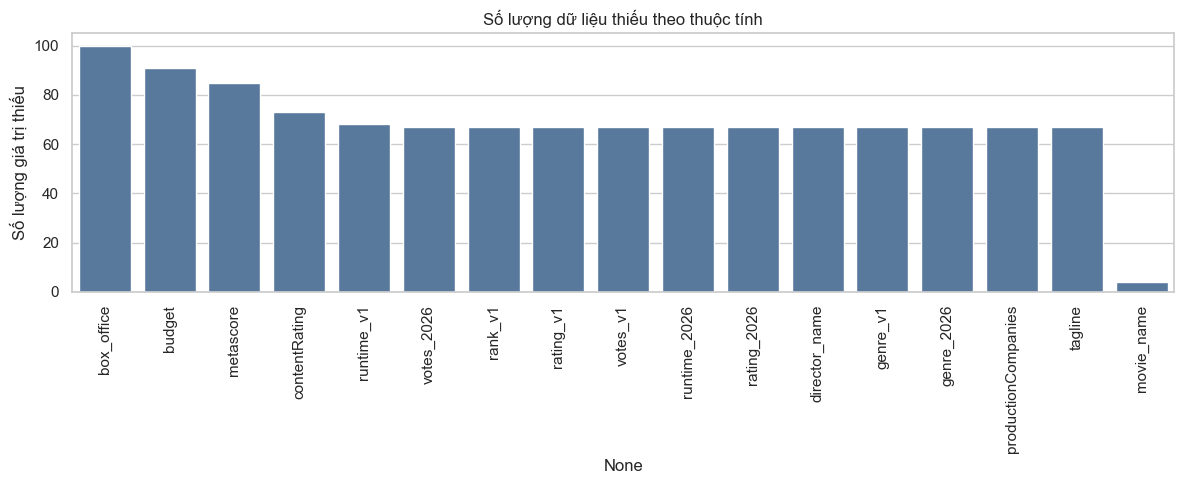

In [5]:
missing = pd.DataFrame({'Số lượng thiếu': df_final.isnull().sum(),
                        'Tỷ lệ thiếu (%)': (df_final.isnull().mean() * 100).round(1)})
missing = missing[missing['Số lượng thiếu'] > 0].sort_values('Số lượng thiếu', ascending=False)
display(missing)

plt.figure(figsize=(12, 5))
sns.barplot(x=missing.index, y=missing['Số lượng thiếu'].values, color='#4C78A8')
plt.xticks(rotation=90)
plt.ylabel('Số lượng giá trị thiếu')
plt.title('Số lượng dữ liệu thiếu theo thuộc tính')
plt.tight_layout(); plt.show()

**Nhận xét:** có 67 dòng thiếu `rating_2026` cùng lúc với toàn bộ nhóm cột của bảng 2026. Đó là những phim có trong danh sách cũ nhưng không ghép được với bảng 2026 theo `title_key` + `year`. Các dòng này **không có nhãn nên không dùng để huấn luyện**. Ở bước 3 ta loại chúng, thay vì điền giá trị cho biến mục tiêu.

### Phân phối biến mục tiêu `rating_2026`

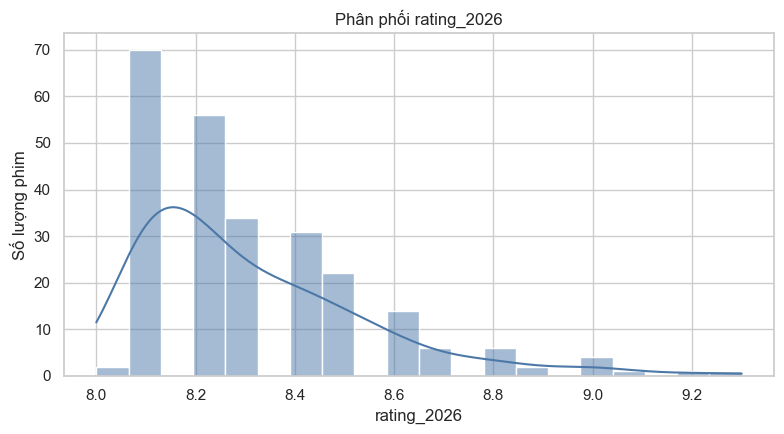

count    250.000
mean       8.314
std        0.233
min        8.000
25%        8.100
50%        8.200
75%        8.400
max        9.300
Name: rating_2026, dtype: float64


In [6]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df_final['rating_2026'].dropna(), bins=20, kde=True, color='#4C78A8')
plt.xlabel('rating_2026'); plt.ylabel('Số lượng phim')
plt.title('Phân phối rating_2026')
plt.tight_layout(); plt.show()
print(df_final['rating_2026'].describe().round(3))

Điểm tập trung ở 8.0–8.4 vì đây là danh sách Top 250, nên khoảng biến thiên hẹp. Điều này giới hạn mức R² có thể đạt được.

### Tương quan

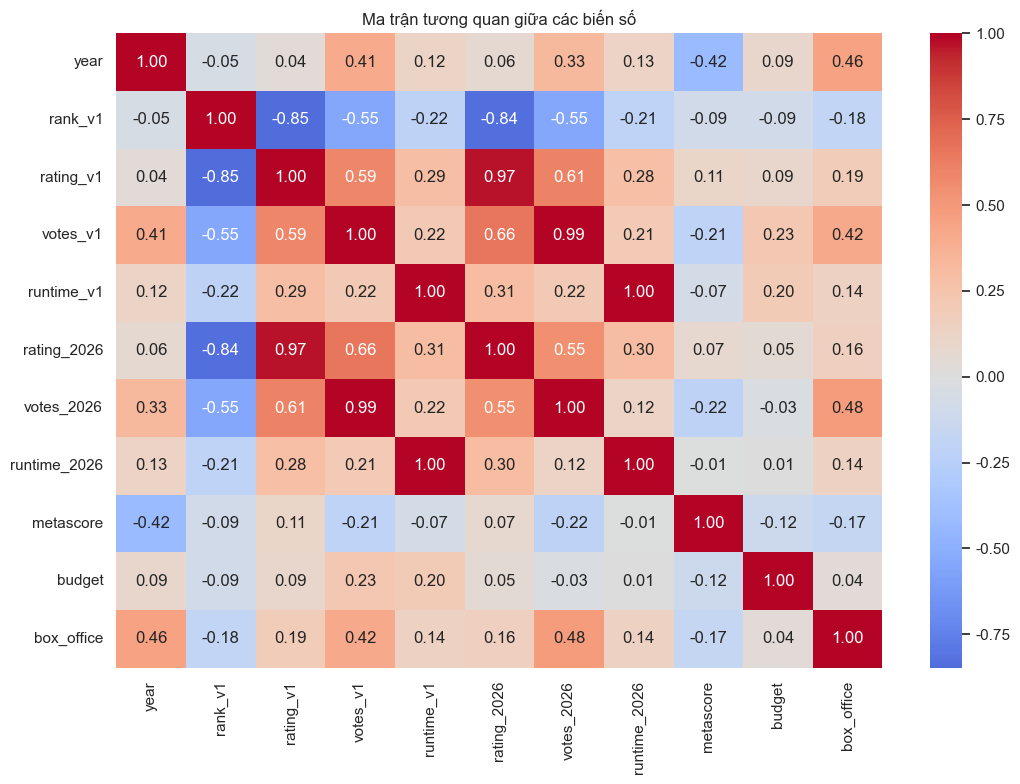

,corr với rating_2026
rating_v1,0.970
votes_v1,0.657
votes_2026,0.549
runtime_v1,0.306
runtime_2026,0.296
box_office,0.157
metascore,0.071
year,0.065
budget,0.050
rank_v1,-0.836


In [7]:
num_cols = ['year', 'rank_v1', 'rating_v1', 'votes_v1', 'runtime_v1', 'rating_2026',
            'votes_2026', 'runtime_2026', 'metascore', 'budget', 'box_office']
corr = df_final[num_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan giữa các biến số')
plt.tight_layout(); plt.show()

display(corr['rating_2026'].drop('rating_2026').sort_values(ascending=False).round(3).to_frame('corr với rating_2026'))

`rating_v1` (≈ 0.97) và `rank_v1` (≈ −0.84) tương quan rất mạnh với `rating_2026`; metascore, year, budget gần như không tương quan tuyến tính. Ta sẽ so sánh với kết quả Feature Importance ở Biểu đồ 6.

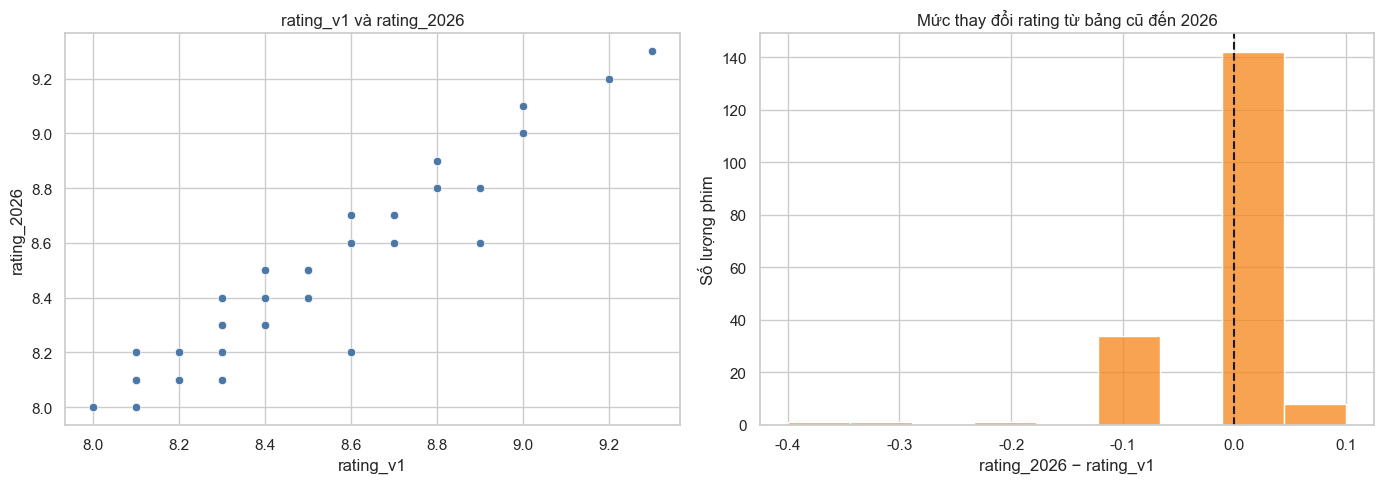

Số phim có cả hai điểm: 187 | thay đổi trung bình = -0.0187 | độ lệch chuẩn = 0.0589
Tỷ lệ phim không đổi điểm: 75.9%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_final, x='rating_v1', y='rating_2026', ax=axes[0], color='#4C78A8')
axes[0].set_title('rating_v1 và rating_2026')

change = (df_final['rating_2026'] - df_final['rating_v1']).dropna()
sns.histplot(change, kde=False, ax=axes[1], color='#F58518')
axes[1].axvline(0, linestyle='--', color='k')
axes[1].set_xlabel('rating_2026 − rating_v1'); axes[1].set_ylabel('Số lượng phim')
axes[1].set_title('Mức thay đổi rating từ bảng cũ đến 2026')
plt.tight_layout(); plt.show()

print(f'Số phim có cả hai điểm: {len(change)} | thay đổi trung bình = {change.mean():.4f} | độ lệch chuẩn = {change.std():.4f}')
print(f'Tỷ lệ phim không đổi điểm: {(change == 0).mean():.1%}')

Phần lớn phim giữ nguyên điểm. Nên bài toán thực chất là dự đoán một **độ trôi nhỏ** quanh `rating_v1`. Điều này giải thích vì sao `rating_v1` chiếm vị trí cao nhất ở Biểu đồ 6.

### Ngoại lệ (IQR)

In [9]:
rows = []
for c in num_cols:
    s = df_final[c].dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({'Thuộc tính': c, 'Q1': q1, 'Q3': q3, 'Ngưỡng dưới': lo, 'Ngưỡng trên': hi,
                 'Số outlier': n_out, 'Tỷ lệ (%)': round(n_out / len(s) * 100, 1)})
display(pd.DataFrame(rows).round(2))

,Thuộc tính,Q1,Q3,Ngưỡng dưới,Ngưỡng trên,Số outlier,Tỷ lệ (%)
0,year,1966.00,2.008000e+03,1.903000e+03,2.071000e+03,0,0.0
1,rank_v1,63.25,1.877500e+02,-1.235000e+02,3.745000e+02,0,0.0
2,rating_v1,8.10,8.400000e+00,7.650000e+00,8.850000e+00,9,3.6
3,votes_v1,209944.75,9.356730e+05,-8.786476e+05,2.024265e+06,4,1.6
4,runtime_v1,107.00,1.450000e+02,5.000000e+01,2.020000e+02,6,2.4
5,rating_2026,8.10,8.400000e+00,7.650000e+00,8.850000e+00,9,3.6
6,votes_2026,251428.75,1.160524e+06,-1.112214e+06,2.524168e+06,5,2.0
7,runtime_2026,109.25,1.477500e+02,5.150000e+01,2.055000e+02,8,3.2
8,metascore,75.00,9.100000e+01,5.100000e+01,1.150000e+02,0,0.0
9,budget,3300000.00,6.300000e+07,-8.625000e+07,1.525500e+08,27,11.9


**Quyết định:** không xóa outlier. Rating cao, ngân sách lớn hoặc doanh thu lớn đều có thể là dữ liệu thật, và mô hình cây không nhạy với giá trị cực đoan như mô hình tuyến tính.

## 3. Tiền xử lý và chia train/test

Các quyết định và lý do:

| Quyết định | Lý do |
|---|---|
| Chỉ giữ phim có `rating_2026` | không điền giá trị cho biến mục tiêu, vì nhãn giả làm sai lệch việc đánh giá |
| Dùng 10 thuộc tính **số** | để vẽ được ngưỡng chia rõ ràng và so sánh trực tiếp hai mô hình |
| Chia 80/20 **trước** khi điền thiếu | tránh rò rỉ thống kê từ test sang train |
| Điền thiếu bằng **median**, fit trên train | đơn giản, bền với outlier |
| Không chuẩn hóa (scale), không one-hot | mô hình dựa trên cây không cần scale; chỉ dùng cột số |

In [10]:
FEATURES = ['year', 'rank_v1', 'rating_v1', 'votes_v1', 'runtime_v1',
            'metascore', 'budget', 'runtime_2026', 'votes_2026', 'box_office']

df_model = df_final.dropna(subset=['rating_2026']).copy()
X = df_model[FEATURES]
y = df_model['rating_2026']
print('Số phim có nhãn:', len(df_model))

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=FEATURES, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=FEATURES, index=X_test_raw.index)

print('Train:', X_train.shape, '| Test:', X_test.shape)
display(X_train_raw.isnull().sum().to_frame('NaN trong X_train (trước khi điền)').T)

Số phim có nhãn: 250
Train: (200, 10) | Test: (50, 10)


,year,rank_v1,rating_v1,votes_v1,runtime_v1,metascore,budget,runtime_2026,votes_2026,box_office
NaN trong X_train (trước khi điền),0,50,50,50,51,13,20,0,0,40


**Lưu ý:** `rating_v1`, `rank_v1`, `votes_v1`, `runtime_v1` thiếu ở các phim mới (không có trong danh sách cũ). Những dòng đó được điền bằng median (ví dụ `rating_v1` = 8.25). Đây là hạn chế sẽ ảnh hưởng đến sai số ở một số phim mới.

### Baseline đơn giản: đoán `rating_2026` bằng `rating_v1`

In [11]:
mask = X_test_raw['rating_v1'].notna()
base_pred = X_test_raw.loc[mask, 'rating_v1']
print(f'Baseline (ŷ = rating_v1) trên {mask.sum()} phim test có rating_v1:')
print(f'  MAE  = {mean_absolute_error(y_test[mask], base_pred):.4f}')
print(f'  RMSE = {np.sqrt(mean_squared_error(y_test[mask], base_pred)):.4f}')
print(f'  R²   = {r2_score(y_test[mask], base_pred):.4f}')

Baseline (ŷ = rating_v1) trên 37 phim test có rating_v1:
  MAE  = 0.0189
  RMSE = 0.0435
  R²   = 0.9395


Con số baseline này dùng để đối chiếu với MAE/RMSE/R² của hai mô hình ở Biểu đồ 3 (lưu ý baseline chỉ tính được trên phim có `rating_v1`).

## 4. Huấn luyện mô hình

Hai mô hình dùng **cùng dữ liệu, cùng phép chia, cùng 300 cây, cùng độ sâu tối đa 6**.

| Tham số | Random Forest | XGBoost |
|---|---|---|
| Số cây | 300 | 300 |
| `max_depth` | 6 | 6 |
| Lấy mẫu | bootstrap, `max_features='sqrt'` | `subsample=0.8`, `colsample_bytree=0.8` |
| Learning rate | không có | 0.05 |
| Cách kết hợp cây | trung bình | cộng dồn tuần tự |

Thời gian fit được đo ngay tại đây và dùng lại ở Biểu đồ 4.

In [12]:
rf_full = RandomForestRegressor(n_estimators=N_TREES, max_depth=6, max_features='sqrt',
                                bootstrap=True, random_state=SEED, n_jobs=-1)
xgb_full = XGBRegressor(n_estimators=N_TREES, learning_rate=0.05, max_depth=6,
                        subsample=0.8, colsample_bytree=0.8,
                        objective='reg:squarederror', tree_method='hist',
                        random_state=SEED, n_jobs=1)

t0 = time.perf_counter(); rf_full.fit(X_train, y_train);  rf_full_seconds = time.perf_counter() - t0
t0 = time.perf_counter(); xgb_full.fit(X_train, y_train); xgb_full_seconds = time.perf_counter() - t0

rf_full_pred = rf_full.predict(X_test)
xgb_full_pred = xgb_full.predict(X_test)

print(f'Đã fit xong. RF: {rf_full_seconds:.3f}s | XGBoost: {xgb_full_seconds:.3f}s')

Đã fit xong. RF: 1.290s | XGBoost: 1.797s


In [13]:
# Mô hình riêng để "mổ xẻ" cơ chế: tắt lấy mẫu ngẫu nhiên (subsample = colsample = 1.0)
# để G, H tính tay trên tập train khớp chính xác với giá trị XGBoost lưu trong cây.
ETA, LAMBDA, GAMMA = 0.05, 1.0, 0.0
xgb_dissect = XGBRegressor(n_estimators=N_TREES, learning_rate=ETA, max_depth=6,
                           reg_lambda=LAMBDA, gamma=GAMMA, subsample=1.0, colsample_bytree=1.0,
                           objective='reg:squarederror', tree_method='hist',
                           random_state=SEED, n_jobs=1)
xgb_dissect.fit(X_train, y_train)
print('Đã fit xong mô hình dùng cho phần demo cơ chế.')

Đã fit xong mô hình dùng cho phần demo cơ chế.


# 5. DEMO – 6 biểu đồ

> **Chuẩn bị trước giờ trình bày:** chạy *Restart & Run All*, lưu output, khi nói chỉ cuộn xuống (đừng chạy lại cell thời gian ở Biểu đồ 4 vì số sẽ đổi mỗi lần chạy).

## Biểu đồ 1. Cây Random Forest

Mỗi cây RF được huấn luyện **độc lập** trên một mẫu bootstrap và dự đoán **trực tiếp rating**. Rừng lấy **trung bình** 300 cây.

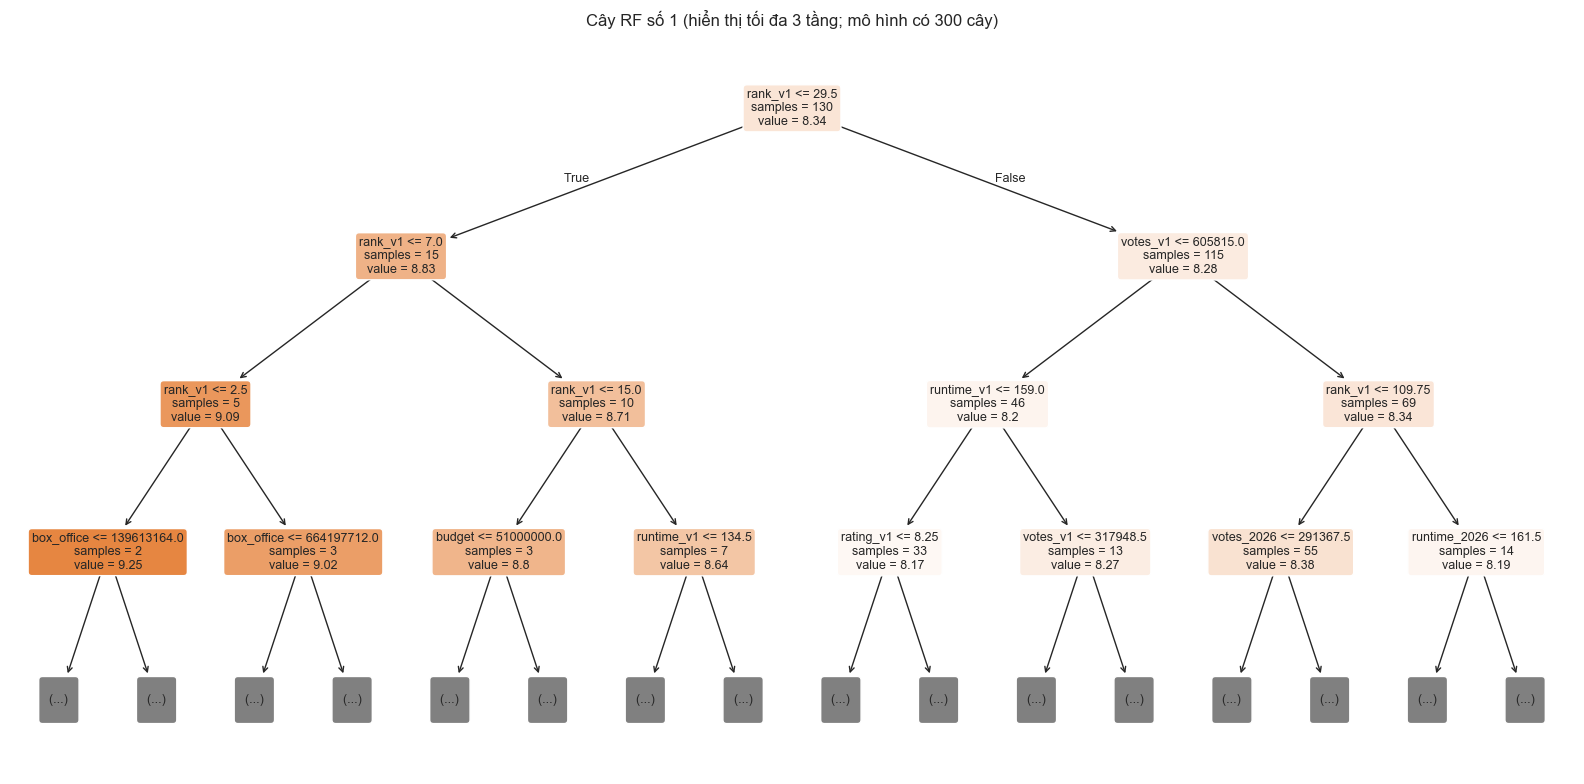

In [14]:
plt.figure(figsize=(16, 8))
plot_tree(rf_full.estimators_[0], feature_names=FEATURES, filled=True, rounded=True,
          impurity=False, precision=2, fontsize=9, max_depth=3)
plt.title('Cây RF số 1 (hiển thị tối đa 3 tầng; mô hình có 300 cây)')
plt.tight_layout(); plt.show()

In [15]:
# Dự đoán của từng cây trên mọi phim test (dùng .to_numpy() vì các cây RF được fit không kèm tên cột)
rf_tree_matrix = np.column_stack([t.predict(X_test.to_numpy()) for t in rf_full.estimators_])

pos = 0                                   # phim test theo dõi (đổi số này để xem phim khác)
trace_idx = X_test.index[pos]
trace_y = float(y_test.iloc[pos])
trace_name = df_model.loc[trace_idx, 'movie_name']

print(f'Phim theo dõi: {trace_name} (index {trace_idx}) | rating thật = {trace_y}')
show = pd.DataFrame({'Cây': np.arange(1, 11), 'Dự đoán của cây': rf_tree_matrix[pos, :10]})
display(show.round(4))
print(f'Trung bình 300 cây = {rf_tree_matrix[pos].mean():.4f}  (rating thật = {trace_y})')

# Chất lượng của từng cây riêng lẻ so với cả rừng
tree_scores = pd.DataFrame({
    'MAE':  [mean_absolute_error(y_test, rf_tree_matrix[:, i]) for i in range(N_TREES)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, rf_tree_matrix[:, i])) for i in range(N_TREES)],
    'R²':   [r2_score(y_test, rf_tree_matrix[:, i]) for i in range(N_TREES)],
})
print('\nPhân bố chất lượng của 300 cây đơn lẻ trên tập test:')
display(tree_scores.describe().loc[['min', 'mean', 'max']].round(4))
print(f'Cả rừng (trung bình 300 cây): MAE = {mean_absolute_error(y_test, rf_full_pred):.4f}, '
      f'R² = {r2_score(y_test, rf_full_pred):.4f}')

Phim theo dõi: Ratatouille (index 188) | rating thật = 8.1


,Cây,Dự đoán của cây
0,1,8.1000
1,2,8.1077
2,3,8.1000
3,4,8.0600
4,5,8.1000
5,6,8.1000
6,7,8.1000
7,8,8.1000
8,9,8.1000
9,10,8.4000


Trung bình 300 cây = 8.1176  (rating thật = 8.1)

Phân bố chất lượng của 300 cây đơn lẻ trên tập test:


,MAE,RMSE,R²
min,0.0537,0.0988,-0.4577
mean,0.0835,0.1391,0.4646
max,0.1421,0.2319,0.7353


Cả rừng (trung bình 300 cây): MAE = 0.0675, R² = 0.6617


Từng cây có chất lượng chênh lệch lớn. Trung bình nhiều cây làm kết quả ổn định hơn (giảm phương sai).

## Biểu đồ 2. Cây XGBoost

Ở XGBoost, **lá không phải là rating** mà là **mức điều chỉnh** cộng thêm vào dự đoán hiện tại. Mỗi nút hiển thị `Gain` và `Cover` (tổng Hessian của các mẫu đi qua nút).

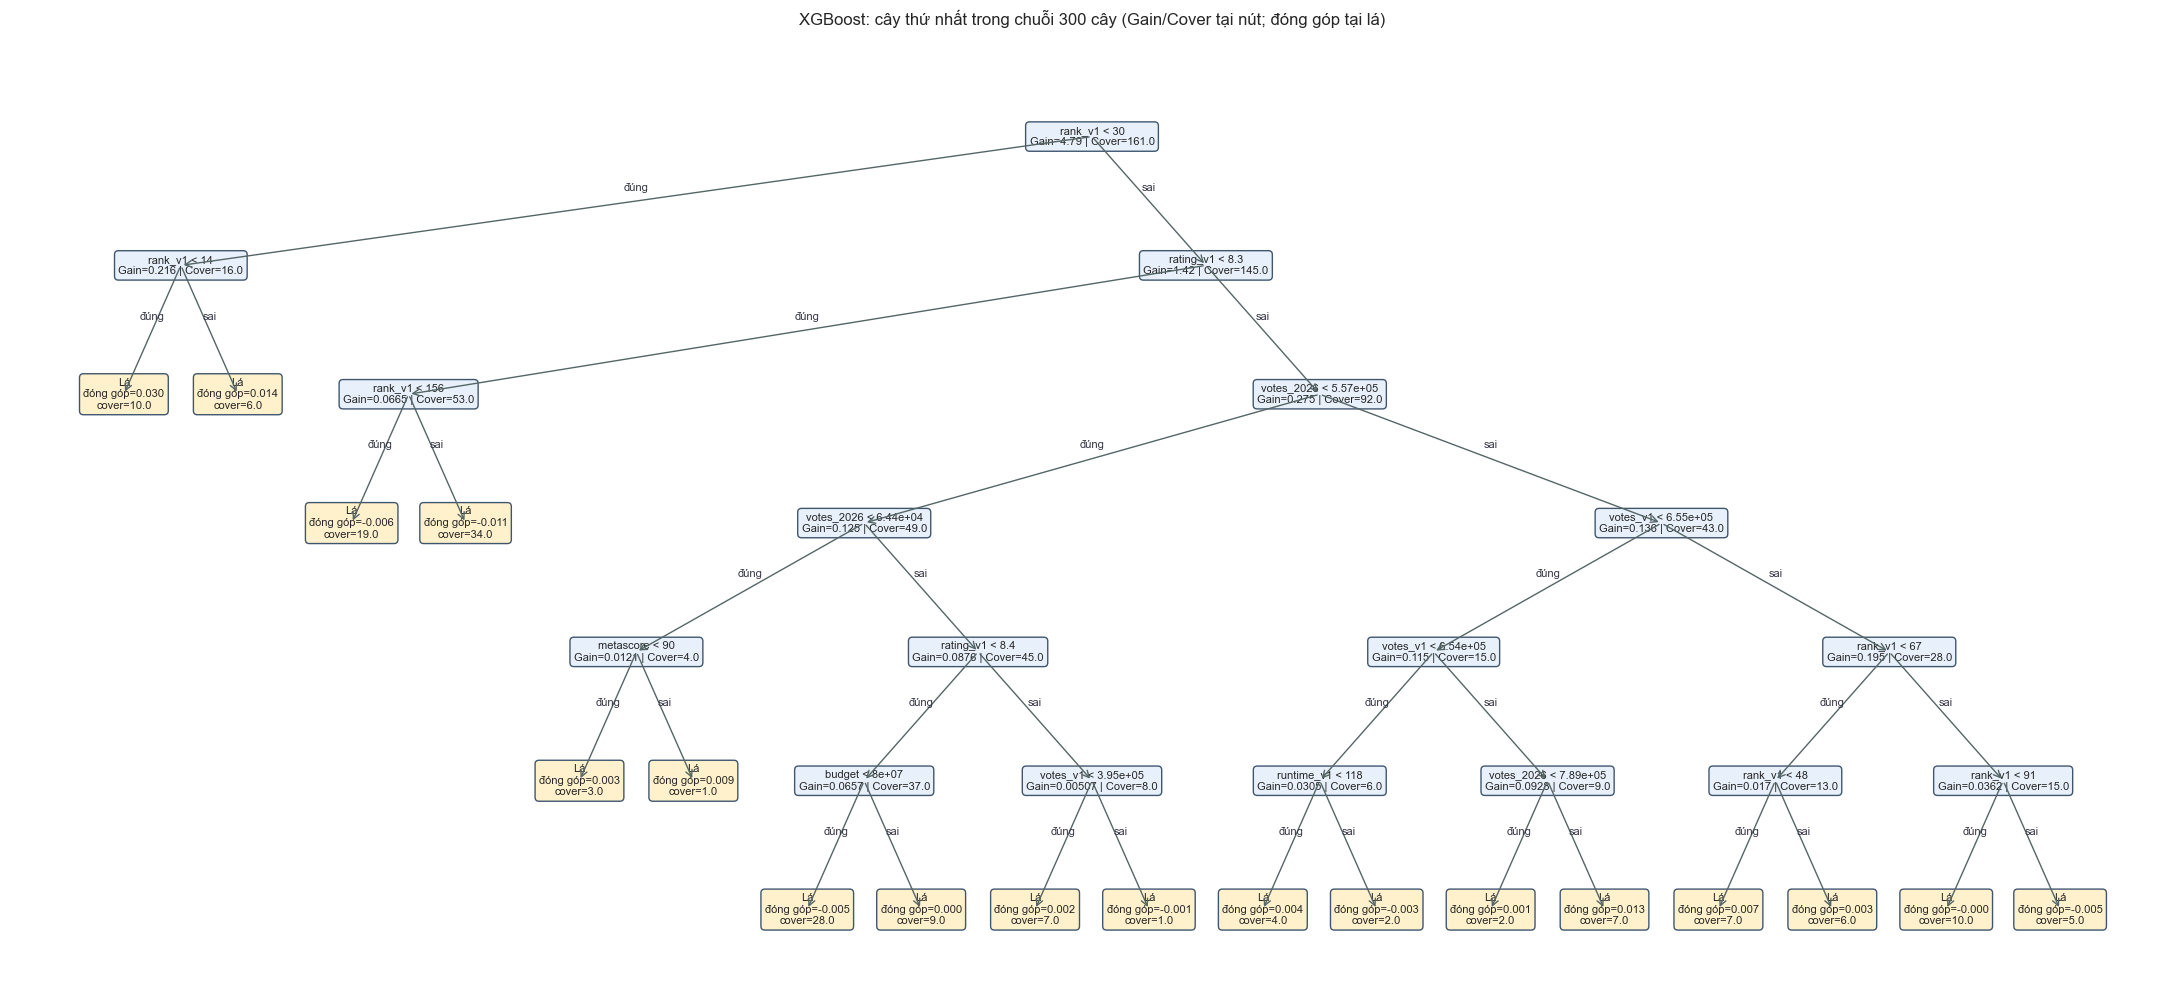

In [16]:
def count_leaves(node):
    if 'leaf' in node:
        return 1
    return sum(count_leaves(c) for c in node.get('children', []))

def draw_xgb_node(ax, node, x_left, x_right, depth=0, parent_xy=None, edge_label=None):
    x, yy = (x_left + x_right) / 2, -depth
    xy = (x, yy)
    if 'leaf' in node:
        label = f"Lá\nđóng góp={node['leaf']:.3f}\ncover={node.get('cover', 0):.1f}"
    else:
        label = (f"{node['split']} < {float(node['split_condition']):.3g}"
                 f"\nGain={node.get('gain', 0):.3g} | Cover={node.get('cover', 0):.1f}")
    ax.text(x, yy, label, ha='center', va='center', fontsize=8,
            bbox=dict(boxstyle='round,pad=0.35', fc='#e8f1fb' if 'leaf' not in node else '#fff1cc', ec='#40566f'))
    if parent_xy is not None:
        ax.annotate('', xy=xy, xytext=parent_xy, arrowprops=dict(arrowstyle='->', color='#566'))
        ax.text((x + parent_xy[0]) / 2, (yy + parent_xy[1]) / 2 + 0.08, edge_label, ha='center', fontsize=8, color='#334')
    if 'leaf' not in node:
        kids = {c['nodeid']: c for c in node['children']}
        left, right = kids[node['yes']], kids[node['no']]
        lw, rw = count_leaves(left), count_leaves(right)
        split_x = x_left + (x_right - x_left) * lw / (lw + rw)
        draw_xgb_node(ax, left, x_left, split_x, depth + 1, xy, 'đúng')
        draw_xgb_node(ax, right, split_x, x_right, depth + 1, xy, 'sai')

tree0 = json.loads(xgb_full.get_booster().get_dump(dump_format='json', with_stats=True)[0])
fig, ax = plt.subplots(figsize=(22, 10))
draw_xgb_node(ax, tree0, 0, count_leaves(tree0))
ax.set_title('XGBoost: cây thứ nhất trong chuỗi 300 cây (Gain/Cover tại nút; đóng góp tại lá)')
ax.set_xlim(-0.5, count_leaves(tree0) + 0.5); ax.set_ylim(-6.5, 0.8); ax.axis('off')
plt.tight_layout(); plt.show()

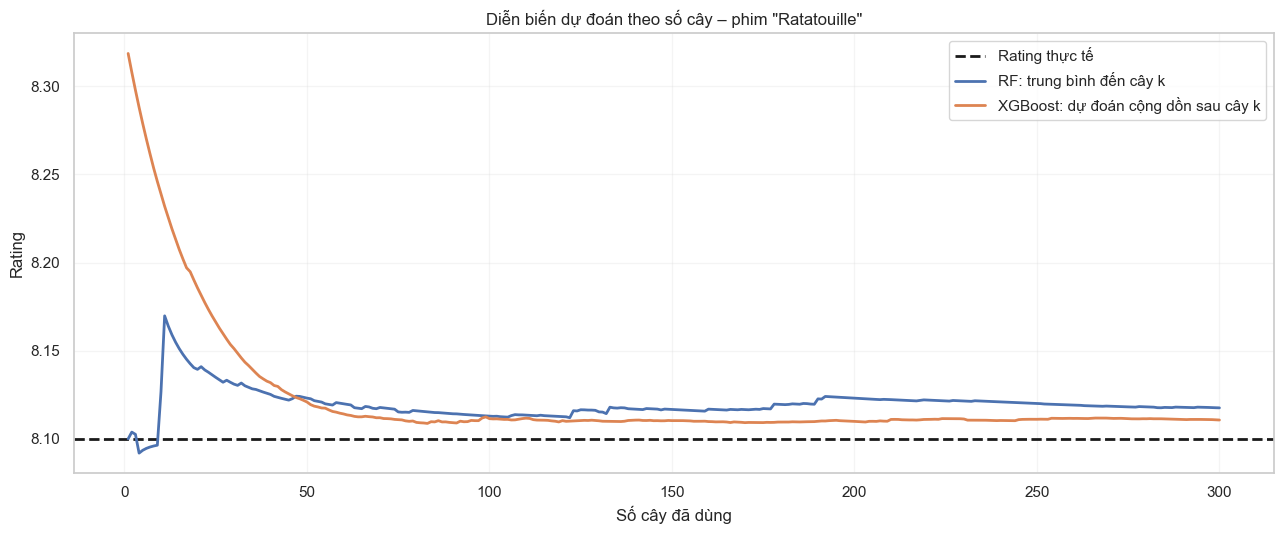

,Số cây,RF: TB đến cây k,XGBoost: cộng dồn,Rating thật
0,1,8.1000,8.3186,8.1
1,2,8.1038,8.3080,8.1
2,3,8.1026,8.2978,8.1
3,5,8.0935,8.2788,8.1
4,10,8.1268,8.2390,8.1
5,25,8.1349,8.1662,8.1
6,50,8.1231,8.1209,8.1
7,100,8.1129,8.1115,8.1
8,200,8.1231,8.1099,8.1
9,300,8.1176,8.1107,8.1


In [17]:
def read_base_score(model):
    # ŷ(0) = base_score. Không dùng predict(iteration_range=(0,0)): (0,0) nghĩa là "dùng TẤT CẢ cây".
    try:
        raw = json.loads(model.get_booster().save_config())['learner']['learner_model_param']['base_score']
        return float(re.findall(r'[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?', str(raw))[0])
    except Exception:
        return None

# Dự đoán cộng dồn sau mỗi cây cho mọi phim test
xgb_cum = np.column_stack([xgb_full.predict(X_test, iteration_range=(0, k)) for k in range(1, N_TREES + 1)])
rf_running = np.cumsum(rf_tree_matrix[pos]) / np.arange(1, N_TREES + 1)

plt.figure(figsize=(13, 5.5))
plt.axhline(trace_y, linestyle='--', linewidth=2, color='k', label='Rating thực tế')
plt.plot(np.arange(1, N_TREES + 1), rf_running, linewidth=2, label='RF: trung bình đến cây k')
plt.plot(np.arange(1, N_TREES + 1), xgb_cum[pos], linewidth=2, label='XGBoost: dự đoán cộng dồn sau cây k')
plt.xlabel('Số cây đã dùng'); plt.ylabel('Rating')
plt.title(f'Diễn biến dự đoán theo số cây – phim "{trace_name}"')
plt.legend(); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

marks = [1, 2, 3, 5, 10, 25, 50, 100, 200, 300]
display(pd.DataFrame({'Số cây': marks,
                      'RF: TB đến cây k': [rf_running[k - 1] for k in marks],
                      'XGBoost: cộng dồn': [xgb_cum[pos, k - 1] for k in marks],
                      'Rating thật': trace_y}).round(4))

**Cách nói:** RF dao động quanh một giá trị ngay từ những cây đầu rồi ổn định. XGBoost xuất phát từ mức trung bình toàn cục rồi **tiến dần** về rating thật nhờ từng bước sửa nhỏ.

## 🔎 DEMO CƠ CHẾ XGBOOST – TỪNG BƯỚC, CÓ SỐ LIỆU

| Phần | Nội dung |
|---|---|
| **A** | Ví dụ **4 bộ phim**, tính tay bằng numpy, chạy 2 vòng boosting |
| **B** | Đúng 5 bước đó trên **dữ liệu phim thật**, đối chiếu với cây XGBoost thật |
| **C** | **Hessian** thay đổi theo mẫu (bài toán phân loại, loss logistic) |

### Năm bước của thuật toán

| Bước | Việc làm | Công thức |
|---|---|---|
| **0** | Khởi tạo dự đoán ban đầu cho mọi mẫu | $\hat y^{(0)}$ = trung bình của $y$ |
| **1** | Tính $g_i, h_i$ (khai triển Taylor bậc 2 của loss) | $g_i=\hat y_i-y_i,\quad h_i=1$ |
| **2** | Chọn feature + ngưỡng chia bằng **Gain** | $\text{Gain}=\frac{G_L^2}{H_L+\lambda}+\frac{G_R^2}{H_R+\lambda}-\frac{G^2}{H+\lambda}-\gamma$ |
| **3** | Tính **trọng số lá** | $w=-\dfrac{G}{H+\lambda}$ |
| **4** | Cập nhật dự đoán với learning rate | $\hat y \leftarrow \hat y + \eta\cdot w$ |
| **5** | Lặp lại: $g,h$ **tính lại** từ $\hat y$ mới, dựng cây kế tiếp | quay về bước 1 |

| Ký hiệu | Ý nghĩa |
|---|---|
| $g_i$ | gradient: đang đoán **cao hay thấp** hơn thực tế, và lệch bao nhiêu |
| $h_i$ | Hessian: độ cong của loss |
| $G,H$ | tổng $g$, tổng $h$ của các mẫu trong một nút/lá |
| $w$ | trọng số (mức điều chỉnh) của một lá |
| $\eta$ | learning rate: chỉ nhận một phần $\eta$ của $w$ |
| $\lambda$ | hệ số phạt L2: làm $w$ nhỏ lại, nhất là ở lá ít mẫu |
| $\gamma$ | "phí" mỗi lần chia nhánh: Gain phải lớn hơn $\gamma$ mới được chia |

> XGBoost báo Gain **không nhân ½** so với công thức trong bài báo. Điều này không đổi việc chọn ngưỡng nào, vì mọi ngưỡng cùng bị nhân một hệ số. Code bên dưới tự kiểm tra.

Để thấy cơ chế thật rõ, em bắt đầu với bốn phim nhỏ. Mỗi phim có một feature là rating_v1, gọi là x, và rating 2026 là y. Phim A có x bằng 8.0 và y bằng 8.0, phim B là 8.1 và 8.2, phim C là 8.5 và 8.6, phim D là 8.7 và 8.8. Em đặt λ bằng 1, γ bằng 0, learning rate η bằng 0.3, và mỗi cây chỉ chia một lần nên có hai lá. Chọn ít phim như vậy để mọi con số đều tính tay được.

### Phần A. 4 bộ phim, tính tay từng bước
Dùng 1 feature `rating_v1` ($x$) để dự đoán `rating_2026` ($y$). Thiết lập: $\lambda=1$, $\gamma=0$, $\eta=0.3$, mỗi cây chia **một lần** (2 lá).

| Phim | x = rating_v1 | y = rating_2026 |
|---|---|---|
| A | 8.0 | 8.0 |
| B | 8.1 | 8.2 |
| C | 8.5 | 8.6 |
| D | 8.7 | 8.8 |

In [18]:
def demo_4_phim():
    ten = ['A', 'B', 'C', 'D']
    x = np.array([8.0, 8.1, 8.5, 8.7])
    y_ = np.array([8.0, 8.2, 8.6, 8.8])
    eta, lam, gamma = 0.3, 1.0, 0.0

    y_hat = np.full(len(y_), y_.mean())
    print('=' * 78)
    print(f'BƯỚC 0 - Khởi tạo: mọi phim đều được dự đoán bằng trung bình y = {y_.mean():.4f}')
    print(f'Loss ban đầu  Σ ½(ŷ-y)² = {0.5 * ((y_hat - y_) ** 2).sum():.4f}')

    for vong in (1, 2):
        print('\n' + '=' * 78)
        print(f'VÒNG {vong}  (cây số {vong})')
        print('=' * 78)

        g = y_hat - y_
        h = np.ones_like(g)
        print('\nBƯỚC 1 - Tính g = ŷ - y và h = 1')
        print(pd.DataFrame({'Phim': ten, 'x': x, 'y': y_, 'ŷ hiện tại': y_hat.round(4),
                            'g = ŷ - y': g.round(4), 'h': h}).to_string(index=False))
        print('  g > 0: đang đoán CAO hơn thực tế (cần hạ xuống) | g < 0: đang đoán THẤP (cần nâng lên)')

        G, H = g.sum(), h.sum()
        ung_vien = []
        for t in (x[:-1] + x[1:]) / 2:
            trai = x < t
            GL, HL = g[trai].sum(), h[trai].sum()
            GR, HR = G - GL, H - HL
            gain = GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam) - gamma
            ung_vien.append({'Ngưỡng (x <)': round(t, 2), 'Nhóm trái': ','.join(np.array(ten)[trai]),
                             'Nhóm phải': ','.join(np.array(ten)[~trai]),
                             'G_L': GL, 'H_L': HL, 'G_R': GR, 'H_R': HR, 'Gain': gain})
        ung_vien = pd.DataFrame(ung_vien)
        chon = ung_vien['Gain'].idxmax()
        print('\nBƯỚC 2 - Thử mọi ngưỡng, Gain = G_L²/(H_L+λ) + G_R²/(H_R+λ) - G²/(H+λ) - γ')
        print(ung_vien.round(4).to_string(index=False))
        t_chon = ung_vien.loc[chon, 'Ngưỡng (x <)']
        print(f'  => Chọn x < {t_chon} vì có Gain lớn nhất ({ung_vien.loc[chon, "Gain"]:.4f})')

        trai = x < t_chon
        GL, HL = g[trai].sum(), h[trai].sum()
        GR, HR = g[~trai].sum(), h[~trai].sum()
        wL, wR = -GL / (HL + lam), -GR / (HR + lam)
        print('\nBƯỚC 3 - Trọng số lá  w = -G / (H + λ)')
        print(f'  Lá trái  {np.array(ten)[trai].tolist()}: G={GL:.4f}, H={HL:.0f} -> w = {wL:.4f}')
        print(f'  Lá phải  {np.array(ten)[~trai].tolist()}: G={GR:.4f}, H={HR:.0f} -> w = {wR:.4f}')
        print(f'  (Nếu λ=0 thì lá trái có w = {-GL / HL:.4f}; λ=1 làm w nhỏ lại -> mô hình thận trọng hơn)')

        w_moi_mau = np.where(trai, wL, wR)
        y_hat_cu = y_hat.copy()
        y_hat = y_hat + eta * w_moi_mau
        print(f'\nBƯỚC 4 - Cập nhật  ŷ_mới = ŷ_cũ + η·w   (η = {eta})')
        print(pd.DataFrame({'Phim': ten, 'ŷ cũ': y_hat_cu.round(4), 'w': w_moi_mau.round(4),
                            'η·w': (eta * w_moi_mau).round(4), 'ŷ mới': y_hat.round(4), 'y thật': y_}).to_string(index=False))
        print(f'  Loss: {0.5 * ((y_hat_cu - y_) ** 2).sum():.4f} -> {0.5 * ((y_hat - y_) ** 2).sum():.4f}')
        print('  BƯỚC 5: sang vòng sau, g được TÍNH LẠI từ ŷ mới (cây sau không học lại y)')

demo_4_phim()

BƯỚC 0 - Khởi tạo: mọi phim đều được dự đoán bằng trung bình y = 8.4000
Loss ban đầu  Σ ½(ŷ-y)² = 0.2000

VÒNG 1  (cây số 1)

BƯỚC 1 - Tính g = ŷ - y và h = 1
Phim   x   y  ŷ hiện tại  g = ŷ - y   h
   A 8.0 8.0         8.4        0.4 1.0
   B 8.1 8.2         8.4        0.2 1.0
   C 8.5 8.6         8.4       -0.2 1.0
   D 8.7 8.8         8.4       -0.4 1.0
  g > 0: đang đoán CAO hơn thực tế (cần hạ xuống) | g < 0: đang đoán THẤP (cần nâng lên)

BƯỚC 2 - Thử mọi ngưỡng, Gain = G_L²/(H_L+λ) + G_R²/(H_R+λ) - G²/(H+λ) - γ
 Ngưỡng (x <) Nhóm trái Nhóm phải  G_L  H_L  G_R  H_R  Gain
         8.05         A     B,C,D  0.4  1.0 -0.4  3.0  0.12
         8.30       A,B       C,D  0.6  2.0 -0.6  2.0  0.24
         8.60     A,B,C         D  0.4  3.0 -0.4  1.0  0.12
  => Chọn x < 8.3 vì có Gain lớn nhất (0.2400)

BƯỚC 3 - Trọng số lá  w = -G / (H + λ)
  Lá trái  ['A', 'B']: G=0.6000, H=2 -> w = -0.2000
  Lá phải  ['C', 'D']: G=-0.6000, H=2 -> w = 0.2000
  (Nếu λ=0 thì lá trái có w = -0.3000; λ=1 là

#### Vẽ từng cây của ví dụ 4 phim
Mỗi vòng có ba hình: **trái** là g của từng phim và ngưỡng được chọn (Bước 1-2); **giữa** là cây với Gain ở nút gốc, G, H, w và η·w ở hai lá (Bước 2-3); **phải** là dự đoán cũ và mới so với y thật (Bước 4). Vòng 2 dùng ŷ mới của vòng 1 để tính lại g (Bước 5).

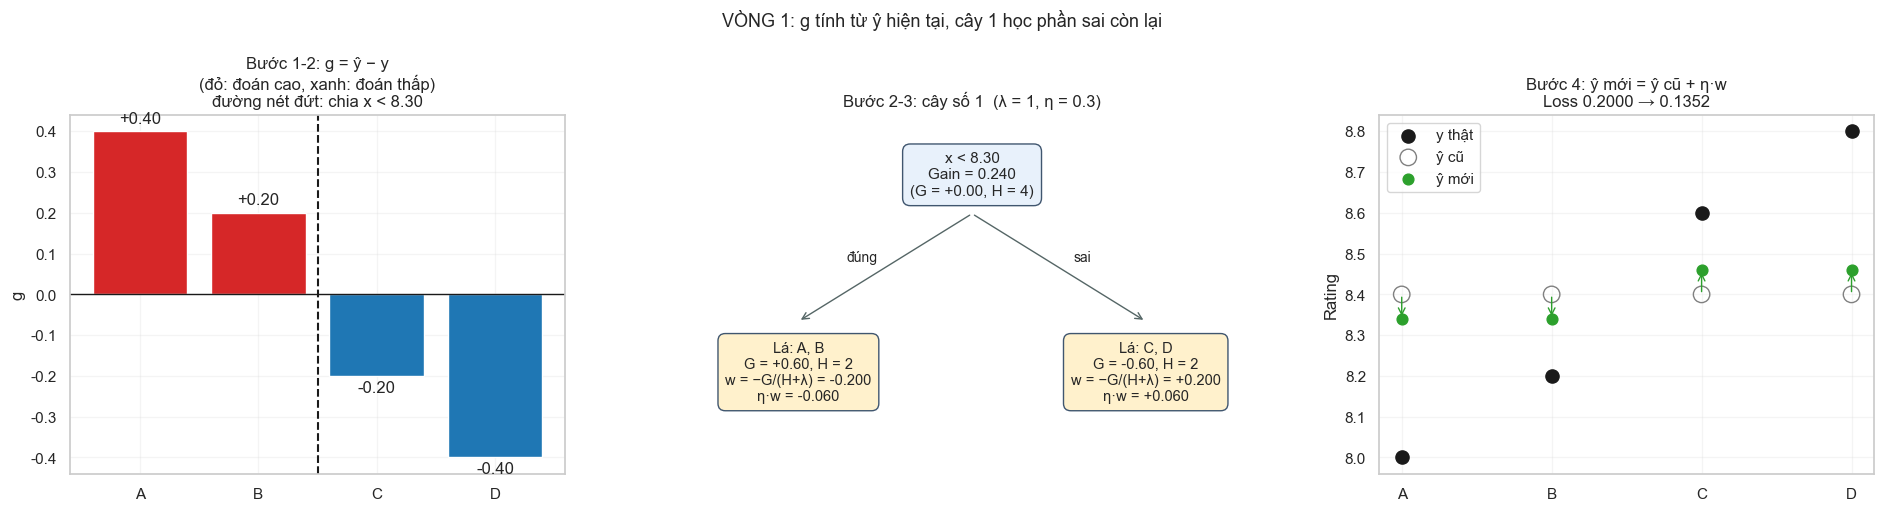

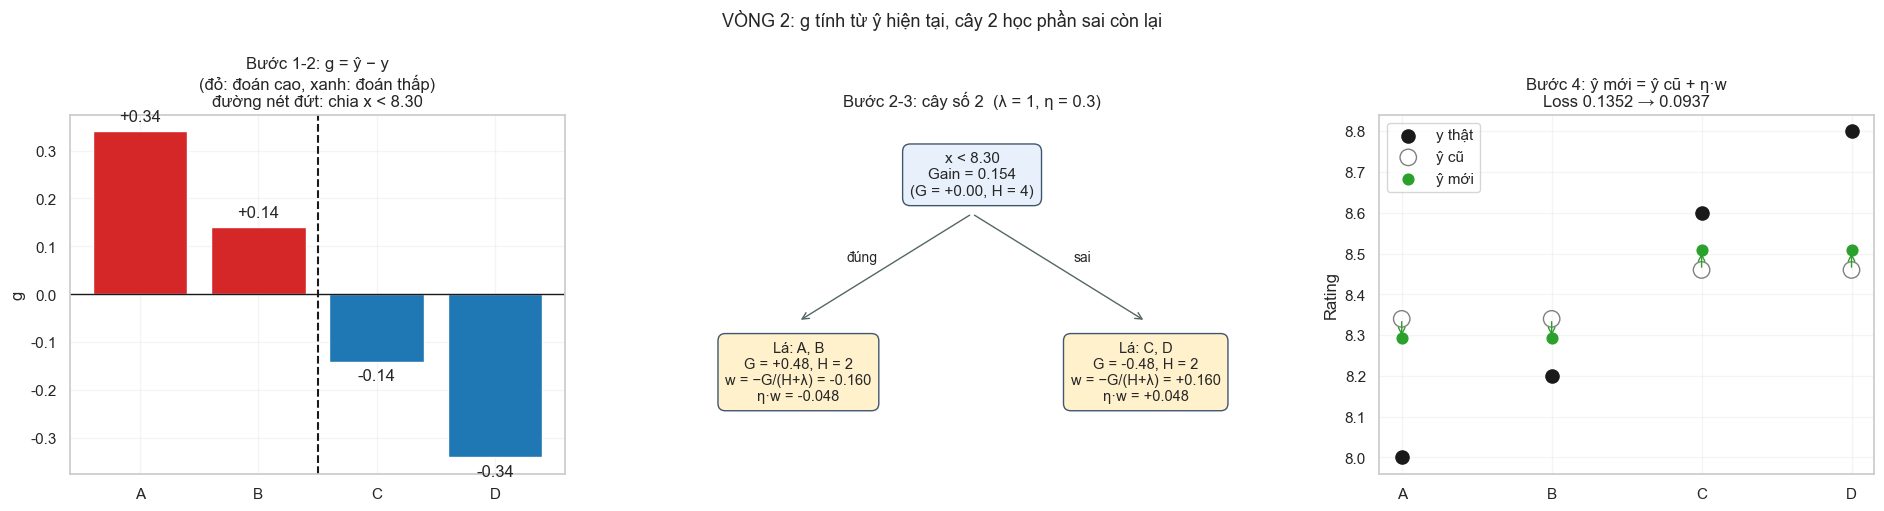

In [19]:
def ve_cay_4_phim():
    """Vẽ từng vòng boosting của ví dụ 4 phim: g (bước 1-2), cây (bước 2-3), dự đoán trước/sau (bước 4)."""
    ten = np.array(['A', 'B', 'C', 'D'])
    x = np.array([8.0, 8.1, 8.5, 8.7])
    y_ = np.array([8.0, 8.2, 8.6, 8.8])
    eta, lam, gamma = 0.3, 1.0, 0.0
    y_hat = np.full(len(y_), y_.mean())

    for vong in (1, 2):
        g = y_hat - y_
        h = np.ones_like(g)
        G, H = g.sum(), h.sum()

        best = None                                   # Bước 2: thử mọi ngưỡng, giữ Gain lớn nhất
        for thr in (x[:-1] + x[1:]) / 2:
            left = x < thr
            GL, HL = g[left].sum(), h[left].sum()
            GR, HR = G - GL, H - HL
            gain = GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam) - gamma
            if best is None or gain > best[0]:
                best = (gain, thr, GL, HL, GR, HR)
        gain, thr, GL, HL, GR, HR = best
        left = x < thr
        wL, wR = -GL / (HL + lam), -GR / (HR + lam)   # Bước 3
        y_new = y_hat + eta * np.where(left, wL, wR)  # Bước 4
        loss_old, loss_new = 0.5 * ((y_hat - y_) ** 2).sum(), 0.5 * ((y_new - y_) ** 2).sum()

        fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={'width_ratios': [1, 1.35, 1]})

        # (1) g của từng phim và ngưỡng được chọn
        ax = axes[0]
        ax.bar(ten, g, color=['#d62728' if v > 0 else '#1f77b4' for v in g])
        ax.axhline(0, color='k', lw=1)
        ax.axvline(left.sum() - 0.5, ls='--', color='k')
        for i, v in enumerate(g):
            ax.text(i, v + (0.02 if v >= 0 else -0.04), f'{v:+.2f}', ha='center')
        ax.set_title(f'Bước 1-2: g = ŷ − y\n(đỏ: đoán cao, xanh: đoán thấp)\nđường nét đứt: chia x < {thr:.2f}')
        ax.set_ylabel('g'); ax.grid(alpha=0.2)

        # (2) cây: nút gốc có Gain, hai lá có G, H, w, η·w
        ax = axes[1]
        ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis('off')
        box = dict(boxstyle='round,pad=0.5', ec='#40566f')
        ax.text(5, 5.0, f'x < {thr:.2f}\nGain = {gain:.3f}\n(G = {(0.0 if abs(G) < 1e-9 else G):+.2f}, H = {H:.0f})',
                ha='center', va='center', fontsize=11, bbox=dict(box, fc='#e8f1fb'))
        for cx, names, G_, H_, w_, lab in [(2.4, ten[left], GL, HL, wL, 'đúng'),
                                           (7.6, ten[~left], GR, HR, wR, 'sai')]:
            ax.annotate('', xy=(cx, 2.55), xytext=(5, 4.35), arrowprops=dict(arrowstyle='->', color='#566'))
            ax.text((cx + 5) / 2 + (-0.35 if cx < 5 else 0.35), 3.55, lab, ha='center', fontsize=10)
            ax.text(cx, 1.7, f"Lá: {', '.join(names)}\nG = {G_:+.2f}, H = {H_:.0f}\nw = −G/(H+λ) = {w_:+.3f}\nη·w = {eta * w_:+.3f}",
                    ha='center', va='center', fontsize=10.5, bbox=dict(box, fc='#fff1cc'))
        ax.set_title(f'Bước 2-3: cây số {vong}  (λ = {lam:g}, η = {eta:g})')

        # (3) dự đoán trước và sau khi cộng η·w
        ax = axes[2]
        ax.scatter(ten, y_, color='k', s=90, label='y thật', zorder=3)
        ax.scatter(ten, y_hat, facecolors='none', edgecolors='gray', s=140, label='ŷ cũ', zorder=2)
        ax.scatter(ten, y_new, color='#2ca02c', s=60, label='ŷ mới', zorder=4)
        for i in range(len(ten)):
            ax.annotate('', xy=(i, y_new[i]), xytext=(i, y_hat[i]), arrowprops=dict(arrowstyle='->', color='#2ca02c'))
        ax.set_title(f'Bước 4: ŷ mới = ŷ cũ + η·w\nLoss {loss_old:.4f} → {loss_new:.4f}')
        ax.set_ylabel('Rating'); ax.legend(); ax.grid(alpha=0.2)

        fig.suptitle(f'VÒNG {vong}: g tính từ ŷ hiện tại, cây {vong} học phần sai còn lại', fontsize=13)
        plt.tight_layout(); plt.show()
        y_hat = y_new                                  # Bước 5: sang vòng sau, g sẽ được tính lại

ve_cay_4_phim()

### Phần B. Năm bước trên dữ liệu phim thật
Dùng `xgb_dissect` (đã fit ở mục 4). Ô dưới đây chỉ **chuẩn bị**: đọc cấu trúc cây thật từ booster, rồi tách dự đoán thành $\hat y^{(0)} + \sum \eta\cdot w$.

In [20]:
booster = xgb_dissect.get_booster()
dumps = [json.loads(t) for t in booster.get_dump(dump_format='json', with_stats=True)]

def leaf_values(node, out=None):
    # Giá trị lá trong dump ĐÃ nhân learning_rate.
    if out is None:
        out = {}
    if 'leaf' in node:
        out[node['nodeid']] = float(node['leaf'])
    else:
        for ch in node['children']:
            leaf_values(ch, out)
    return out

leaf_val = [leaf_values(t) for t in dumps]
leaf_id_train = np.asarray(xgb_dissect.apply(X_train)).astype(int)    # (n_train, n_trees)
leaf_id_test = np.asarray(xgb_dissect.apply(X_test)).astype(int)
n_train = len(X_train)
y_tr = y_train.to_numpy(dtype=float)

contrib_train = np.column_stack([pd.Series(leaf_id_train[:, k]).map(leaf_val[k]).to_numpy(dtype=float)
                                 for k in range(N_TREES)])

pred_final_train = np.asarray(xgb_dissect.predict(X_train), dtype=float)
base = read_base_score(xgb_dissect)
if base is not None and np.abs(base + contrib_train.sum(axis=1) - pred_final_train).max() > 1e-3:
    base = None
if base is None:                                  # suy ngược từ dữ liệu nếu đọc config không khớp
    base = float(np.median(pred_final_train - contrib_train.sum(axis=1)))
recon_err = np.abs(base + contrib_train.sum(axis=1) - pred_final_train).max()

cum_train = base + np.cumsum(contrib_train, axis=1)                    # ŷ SAU cây k
pred_before_train = np.column_stack([np.full(n_train, base), cum_train[:, :-1]])   # ŷ TRƯỚC cây k

# Phim test theo dõi (cùng phim ở Biểu đồ 1, 2)
contrib_test = np.array([leaf_val[k][leaf_id_test[pos, k]] for k in range(N_TREES)])
pred_after_test = base + np.cumsum(contrib_test)
pred_before_test = np.concatenate([[base], pred_after_test[:-1]])

print(f'Số mẫu train: {n_train} | số cây: {N_TREES} | η = {ETA} | λ = {LAMBDA} | γ = {GAMMA}')
print(f'Phim theo dõi: {trace_name} | rating thực tế y = {trace_y}')
print(f'Kiểm chứng tách dự đoán ŷ(0) + Σ(η·w) so với predict(): sai lệch lớn nhất = {recon_err:.2e}',
      '✓' if recon_err < 1e-3 else '✗')

Số mẫu train: 200 | số cây: 300 | η = 0.05 | λ = 1.0 | γ = 0.0
Phim theo dõi: Ratatouille | rating thực tế y = 8.1
Kiểm chứng tách dự đoán ŷ(0) + Σ(η·w) so với predict(): sai lệch lớn nhất = 1.40e-05 ✓


#### Bước 0. Khởi tạo $\hat y^{(0)}$
Chưa có cây nào. Với hồi quy, XGBoost bắt đầu bằng `base_score`, thường là **trung bình của $y$** trên train. Mọi phim có cùng dự đoán ban đầu.

In [21]:
print('BƯỚC 0 - DỰ ĐOÁN BAN ĐẦU (chưa có cây nào)')
print(f'  ŷ(0) = base_score          = {base:.6f}')
print(f'  Trung bình y của tập train = {y_tr.mean():.6f}   (hai số này xấp xỉ nhau)')
print(f'  Phim theo dõi: y = {trace_y:.4f}  ->  sai lệch ban đầu ŷ(0) - y = {base - trace_y:+.4f}')

BƯỚC 0 - DỰ ĐOÁN BAN ĐẦU (chưa có cây nào)
  ŷ(0) = base_score          = 8.329500
  Trung bình y của tập train = 8.329500   (hai số này xấp xỉ nhau)
  Phim theo dõi: y = 8.1000  ->  sai lệch ban đầu ŷ(0) - y = +0.2295


#### Bước 1. Tính $g_i$ và $h_i$ cho từng phim (cây 1)
Với loss bình phương $L=\tfrac12(\hat y-y)^2$: $g_i=\hat y_i-y_i$ ($g>0$: đoán cao; $g<0$: đoán thấp) và $h_i=1$.
Khai triển Taylor bậc 2: $L(\hat y+w)\approx L(\hat y)+g\,w+\tfrac12 h\,w^2$. Cây mới chọn $w$ làm vế phải nhỏ nhất.

In [22]:
g1 = pred_before_train[:, 0] - y_tr
h1 = np.ones_like(g1)

print('BƯỚC 1 - g và h của 8 phim train đầu tiên (trước cây 1)')
display(pd.DataFrame({'y thật': y_tr[:8], 'ŷ hiện tại': pred_before_train[:8, 0],
                      'g = ŷ - y': g1[:8], 'h': h1[:8]}).round(4))
print(f'Toàn bộ {n_train} phim: Σg = {g1.sum():.4f} (≈ 0 vì ŷ(0) là trung bình), Σh = {h1.sum():.0f}, trung bình |g| = {np.abs(g1).mean():.4f}')
print(f'Phim theo dõi: g = {pred_before_test[0]:.4f} - {trace_y:.4f} = {pred_before_test[0] - trace_y:+.4f}')

BƯỚC 1 - g và h của 8 phim train đầu tiên (trước cây 1)


,y thật,ŷ hiện tại,g = ŷ - y,h
0,8.0,8.3295,0.3295,1.0
1,8.1,8.3295,0.2295,1.0
2,8.3,8.3295,0.0295,1.0
3,8.1,8.3295,0.2295,1.0
4,8.5,8.3295,-0.1705,1.0
5,8.7,8.3295,-0.3705,1.0
6,8.1,8.3295,0.2295,1.0
7,8.1,8.3295,0.2295,1.0


Toàn bộ 200 phim: Σg = -0.0000 (≈ 0 vì ŷ(0) là trung bình), Σh = 200, trung bình |g| = 0.1852
Phim theo dõi: g = 8.3295 - 8.1000 = +0.2295


#### Bước 2. Chọn feature và ngưỡng chia bằng Gain (nút gốc của cây 1)
Quét mọi ứng viên (feature, ngưỡng), chia các phim thành nhóm trái/phải rồi tính Gain (*Exact Greedy*). Gain lớn nghĩa là gom được các phim có $g$ cùng dấu vào cùng một nhóm.

In [23]:
def scan_splits(X_df, g, lam, gamma=0.0):
    rows = []
    G, H = g.sum(), float(len(g))
    for f in X_df.columns:
        v = X_df[f].to_numpy(float)
        order = np.argsort(v, kind='stable')
        vs, cg = v[order], np.cumsum(g[order])
        for i in np.where(vs[1:] > vs[:-1])[0]:
            GL, HL = cg[i], i + 1.0
            GR, HR = G - GL, H - HL
            gain = GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam) - gamma
            rows.append((f, (vs[i] + vs[i + 1]) / 2, GL, HL, GR, HR, gain))
    out = pd.DataFrame(rows, columns=['Feature', 'Ngưỡng (<)', 'G_L', 'H_L', 'G_R', 'H_R', 'Gain'])
    return out.sort_values('Gain', ascending=False).reset_index(drop=True)

root = dumps[0]
GAIN_SCALE = 1.0
if 'leaf' in root:
    print('Cây 1 không chia được (chỉ có 1 lá).')
else:
    kids = {c['nodeid']: c for c in root['children']}
    mL = np.isin(leaf_id_train[:, 0], list(leaf_values(kids[root['yes']]).keys()))
    GL, HL = g1[mL].sum(), float(mL.sum())
    GR, HR = g1[~mL].sum(), float((~mL).sum())
    Gt, Ht = g1.sum(), float(n_train)
    term = GL**2 / (HL + LAMBDA) + GR**2 / (HR + LAMBDA) - Gt**2 / (Ht + LAMBDA)
    gain_dump = float(root['gain'])
    if np.isclose(term, gain_dump, rtol=1e-3):
        GAIN_SCALE = 1.0
    elif np.isclose(0.5 * term, gain_dump, rtol=1e-3):
        GAIN_SCALE = 0.5

    scan = scan_splits(X_train, g1, LAMBDA, GAMMA)
    scan['Gain'] = scan['Gain'] * GAIN_SCALE
    print('BƯỚC 2 - Quét mọi ngưỡng: 5 ứng viên có Gain cao nhất (nút gốc, cây 1)')
    display(scan.head(5).round(4))

    print(f"Phép chia XGBoost chọn: {root['split']} < {float(root['split_condition']):.6g}")
    print(f'  Trái : G_L = {GL:+.4f}, H_L = {HL:.0f}  ->  G_L²/(H_L+λ) = {GL**2 / (HL + LAMBDA):.4f}')
    print(f'  Phải : G_R = {GR:+.4f}, H_R = {HR:.0f}  ->  G_R²/(H_R+λ) = {GR**2 / (HR + LAMBDA):.4f}')
    print(f'  Cha  : G   = {Gt:+.4f}, H   = {Ht:.0f}  ->  G²/(H+λ)     = {Gt**2 / (Ht + LAMBDA):.4f}')
    print(f'  Gain tính tay (trái + phải - cha - γ) = {term - GAMMA:.4f}')
    print(f'  Gain XGBoost báo cáo (dump)           = {gain_dump:.4f}')
    print('  ✓ Khớp công thức (XGBoost báo Gain KHÔNG nhân ½).' if GAIN_SCALE == 1.0
          else '  ✓ Khớp công thức có hệ số ½.')
    print(f"  Ứng viên Gain cao nhất khi quét chính xác: {scan.loc[0, 'Feature']} < {scan.loc[0, 'Ngưỡng (<)']:.6g}"
          f" (Gain = {scan.loc[0, 'Gain']:.4f})")
    print('  (tree_method="hist" gom giá trị vào bin nên thỉnh thoảng chọn ngưỡng hơi khác Exact Greedy)')

BƯỚC 2 - Quét mọi ngưỡng: 5 ứng viên có Gain cao nhất (nút gốc, cây 1)


,Feature,Ngưỡng (<),G_L,H_L,G_R,H_R,Gain
0,rank_v1,29.5,-10.2100,20.0,10.2100,180.0,5.5399
1,rank_v1,31.0,-10.3805,21.0,10.3805,179.0,5.4966
2,rank_v1,28.0,-9.9395,19.0,9.9395,181.0,5.4825
3,rank_v1,32.5,-10.5510,22.0,10.5510,178.0,5.4621
4,rank_v1,35.0,-10.7215,23.0,10.7215,177.0,5.4354


Phép chia XGBoost chọn: rank_v1 < 30
  Trái : G_L = -10.2100, H_L = 20  ->  G_L²/(H_L+λ) = 4.9640
  Phải : G_R = +10.2100, H_R = 180  ->  G_R²/(H_R+λ) = 0.5759
  Cha  : G   = -0.0000, H   = 200  ->  G²/(H+λ)     = 0.0000
  Gain tính tay (trái + phải - cha - γ) = 5.5399
  Gain XGBoost báo cáo (dump)           = 5.5399
  ✓ Khớp công thức (XGBoost báo Gain KHÔNG nhân ½).
  Ứng viên Gain cao nhất khi quét chính xác: rank_v1 < 29.5 (Gain = 5.5399)
  (tree_method="hist" gom giá trị vào bin nên thỉnh thoảng chọn ngưỡng hơi khác Exact Greedy)


#### Bước 3. Trọng số của từng lá
$$w=-\frac{G}{H+\lambda}\qquad(G=\sum g_i,\ H=\sum h_i\ \text{của các phim trong lá})$$
Giá trị lá XGBoost lưu **đã nhân sẵn $\eta$**, nên so sánh $\eta\cdot w$ (công thức) với giá trị lá trong cây.

In [24]:
t = 0   # cây số 1
leaf_tbl = (pd.DataFrame({'Leaf ID': leaf_id_train[:, t], 'g': g1})
            .groupby('Leaf ID').agg(**{'Số mẫu': ('g', 'size'), 'G': ('g', 'sum')}).reset_index())
leaf_tbl['H'] = leaf_tbl['Số mẫu'].astype(float)
leaf_tbl['w = -G/(H+λ)'] = -leaf_tbl['G'] / (leaf_tbl['H'] + LAMBDA)
leaf_tbl['η·w (công thức)'] = ETA * leaf_tbl['w = -G/(H+λ)']
leaf_tbl['Giá trị lá trong cây'] = leaf_tbl['Leaf ID'].map(leaf_val[t])
leaf_tbl['Lệch'] = leaf_tbl['η·w (công thức)'] - leaf_tbl['Giá trị lá trong cây']

print('BƯỚC 3 - Trọng số của MỌI lá trong cây 1')
display(leaf_tbl.round(6))
print(f"Lệch lớn nhất giữa công thức và cây thật: {leaf_tbl['Lệch'].abs().max():.2e}",
      '✓' if leaf_tbl['Lệch'].abs().max() < 1e-4 else '✗')

my_leaf = int(leaf_id_test[pos, t])
r = leaf_tbl[leaf_tbl['Leaf ID'] == my_leaf].iloc[0]
print(f"\nPhim theo dõi rơi vào lá {my_leaf}: {int(r['Số mẫu'])} phim train, G = {r['G']:+.4f}, H = {r['H']:.0f}")
print(f"  w = -G/(H+λ) = -({r['G']:+.4f})/({r['H']:.0f}+{LAMBDA}) = {r['w = -G/(H+λ)']:+.6f}")
print(f"  (Nếu λ = 0 thì w = {-r['G'] / r['H']:+.6f}; λ làm w nhỏ lại để mô hình thận trọng hơn)")

BƯỚC 3 - Trọng số của MỌI lá trong cây 1


,Leaf ID,Số mẫu,G,H,w = -G/(H+λ),η·w (công thức),Giá trị lá trong cây,Lệch
0,3,12,-7.7460,12.0,0.595846,0.029792,0.029792,0.0
1,4,8,-2.4640,8.0,0.273778,0.013689,0.013689,0.0
2,7,21,2.8195,21.0,-0.128159,-0.006408,-0.006408,0.0
3,12,1,0.1295,1.0,-0.064750,-0.003238,-0.003238,0.0
4,17,1,0.1295,1.0,-0.064750,-0.003238,-0.003238,0.0
5,18,43,9.8685,43.0,-0.224284,-0.011214,-0.011214,-0.0
6,23,1,-0.0705,1.0,0.035250,0.001763,0.001762,0.0
7,24,10,-2.0050,10.0,0.182273,0.009114,0.009114,0.0
8,25,1,-0.0705,1.0,0.035250,0.001763,0.001762,0.0
9,26,1,0.0295,1.0,-0.014750,-0.000737,-0.000738,0.0


Lệch lớn nhất giữa công thức và cây thật: 2.59e-08 ✓

Phim theo dõi rơi vào lá 18: 43 phim train, G = +9.8685, H = 43
  w = -G/(H+λ) = -(+9.8685)/(43+1.0) = -0.224284
  (Nếu λ = 0 thì w = -0.229500; λ làm w nhỏ lại để mô hình thận trọng hơn)


#### Bước 4. Cập nhật dự đoán với learning rate
$$\hat y_{\text{mới}}=\hat y_{\text{cũ}}+\eta\cdot w$$
Chỉ nhận một phần $\eta$ của mức sửa. Nếu cây này nhìn sai một chút, các cây sau vẫn còn chỗ để sửa.

In [25]:
w_my = float(r['w = -G/(H+λ)'])
print('BƯỚC 4 - Cập nhật dự đoán của phim đang theo dõi sau cây 1')
print(f'  ŷ cũ        = {pred_before_test[0]:.6f}')
print(f'  w           = {w_my:+.6f}')
print(f'  η·w         = {ETA} × {w_my:+.6f} = {ETA * w_my:+.6f}')
print(f'  ŷ mới       = {pred_before_test[0]:.6f} + ({ETA * w_my:+.6f}) = {pred_before_test[0] + ETA * w_my:.6f}')
print(f'  ŷ sau cây 1 (lấy từ XGBoost thật) = {pred_after_test[0]:.6f}')
print(f'  Sai số |y - ŷ|: {abs(trace_y - pred_before_test[0]):.4f} -> {abs(trace_y - pred_after_test[0]):.4f}')

loss_before = 0.5 * np.mean((pred_before_train[:, 0] - y_tr) ** 2)
loss_after = 0.5 * np.mean((cum_train[:, 0] - y_tr) ** 2)
print(f'\nToàn bộ tập train: loss trung bình ½(ŷ-y)² giảm {loss_before:.6f} -> {loss_after:.6f} sau cây 1')

BƯỚC 4 - Cập nhật dự đoán của phim đang theo dõi sau cây 1
  ŷ cũ        = 8.329500
  w           = -0.224284
  η·w         = 0.05 × -0.224284 = -0.011214
  ŷ mới       = 8.329500 + (-0.011214) = 8.318286
  ŷ sau cây 1 (lấy từ XGBoost thật) = 8.318286
  Sai số |y - ŷ|: 0.2295 -> 0.2183

Toàn bộ tập train: loss trung bình ½(ŷ-y)² giảm 0.028640 -> 0.026447 sau cây 1


#### Bước 5. Lặp lại: $g$ được **tính lại** từ $\hat y$ mới
Cây 2 không học lại $y$. Nó học $g=\hat y_{\text{mới}}-y$, tức **phần sai còn sót lại** sau cây 1. Ô dưới chạy lại bước 1 → 4 cho **toàn bộ 300 cây**, in chi tiết 3 cây đầu và các mốc quan trọng.

In [26]:
rows = []
for k in range(N_TREES):
    g = pred_before_train[:, k] - y_tr                   # Bước 1: g tính lại từ ŷ hiện tại
    lid = leaf_id_train[:, k]
    mask = lid == leaf_id_test[pos, k]
    G_, H_ = float(g[mask].sum()), float(mask.sum())     # Bước 3: G, H của lá chứa phim theo dõi
    w = -G_ / (H_ + LAMBDA)
    w_dump = leaf_val[k][leaf_id_test[pos, k]]

    rt = dumps[k]                                         # Bước 2: Gain tại nút gốc
    gain_hand = gain_dump_k = np.nan
    split = ''
    if 'leaf' not in rt:
        kd = {c['nodeid']: c for c in rt['children']}
        mLk = np.isin(lid, list(leaf_values(kd[rt['yes']]).keys()))
        GLk, HLk = float(g[mLk].sum()), float(mLk.sum())
        GRk, HRk = float(g.sum()) - GLk, float(len(g)) - HLk
        tk = GLk**2 / (HLk + LAMBDA) + GRk**2 / (HRk + LAMBDA) - float(g.sum())**2 / (len(g) + LAMBDA)
        gain_hand = GAIN_SCALE * tk - GAMMA
        gain_dump_k = float(rt.get('gain', np.nan))
        split = f"{rt['split']} < {float(rt['split_condition']):.6g}"

    rows.append({
        'Cây': k + 1, 'ŷ trước cây': pred_before_test[k], 'y thật': trace_y,
        'g = ŷ - y': pred_before_test[k] - trace_y, 'h': 1.0,
        'Split gốc': split, 'Gain (tính tay)': gain_hand, 'Gain (cây thật)': gain_dump_k,
        'Leaf ID': int(leaf_id_test[pos, k]), 'Số mẫu trong lá': int(mask.sum()),
        'G lá': G_, 'H lá': H_, 'w = -G/(H+λ)': w,
        'η·w (công thức)': ETA * w, 'Giá trị lá trong cây': w_dump,
        'ŷ sau cây': pred_after_test[k], 'Sai số y - ŷ': trace_y - pred_after_test[k],
        'Loss train TB': 0.5 * np.mean((cum_train[:, k] - y_tr) ** 2),
    })
detail = pd.DataFrame(rows)

for _, r_ in detail.head(3).iterrows():
    print(f"\n🌳 CÂY {int(r_['Cây'])}")
    print(f"  Bước 1: ŷ trước cây = {r_['ŷ trước cây']:.6f}" + ('  (= ŷ(0))' if r_['Cây'] == 1 else '  (= ŷ sau cây trước)')
          + f" | y = {r_['y thật']:.4f} | g = ŷ - y = {r_['g = ŷ - y']:+.6f} | h = 1")
    print(f"  Bước 2: nút gốc chia {r_['Split gốc']} | Gain = {r_['Gain (cây thật)']:.4f}")
    print(f"  Bước 3: phim rơi vào lá {int(r_['Leaf ID'])} ({int(r_['Số mẫu trong lá'])} phim train), "
          f"G = {r_['G lá']:+.4f}, H = {r_['H lá']:.0f}, w = -G/(H+λ) = {r_['w = -G/(H+λ)']:+.6f}")
    print(f"  Bước 4: η·w = {r_['η·w (công thức)']:+.6f} (lá trong cây: {r_['Giá trị lá trong cây']:+.6f})"
          f" -> ŷ mới = {r_['ŷ sau cây']:.6f} | sai số y - ŷ = {r_['Sai số y - ŷ']:+.6f}")

print('\nBẢNG CÁC MỐC QUAN TRỌNG')
display(detail[detail['Cây'].isin([1, 2, 3, 5, 10, 25, 50, 100, 200, 300])][[
    'Cây', 'ŷ trước cây', 'g = ŷ - y', 'G lá', 'H lá', 'w = -G/(H+λ)', 'η·w (công thức)',
    'Giá trị lá trong cây', 'ŷ sau cây', 'Sai số y - ŷ', 'Loss train TB']].round(6))


🌳 CÂY 1
  Bước 1: ŷ trước cây = 8.329500  (= ŷ(0)) | y = 8.1000 | g = ŷ - y = +0.229500 | h = 1
  Bước 2: nút gốc chia rank_v1 < 30 | Gain = 5.5399
  Bước 3: phim rơi vào lá 18 (43 phim train), G = +9.8685, H = 43, w = -G/(H+λ) = -0.224284
  Bước 4: η·w = -0.011214 (lá trong cây: -0.011214) -> ŷ mới = 8.318286 | sai số y - ŷ = -0.218286

🌳 CÂY 2
  Bước 1: ŷ trước cây = 8.318286  (= ŷ sau cây trước) | y = 8.1000 | g = ŷ - y = +0.218286 | h = 1
  Bước 2: nút gốc chia rank_v1 < 30 | Gain = 5.0397
  Bước 3: phim rơi vào lá 8 (45 phim train), G = +9.6388, H = 45, w = -G/(H+λ) = -0.209539
  Bước 4: η·w = -0.010477 (lá trong cây: -0.010477) -> ŷ mới = 8.307809 | sai số y - ŷ = -0.207809

🌳 CÂY 3
  Bước 1: ŷ trước cây = 8.307809  (= ŷ sau cây trước) | y = 8.1000 | g = ŷ - y = +0.207809 | h = 1
  Bước 2: nút gốc chia rank_v1 < 30 | Gain = 4.5839
  Bước 3: phim rơi vào lá 18 (43 phim train), G = +8.9358, H = 43, w = -G/(H+λ) = -0.203086
  Bước 4: η·w = -0.010154 (lá trong cây: -0.010154) -> ŷ m

,Cây,ŷ trước cây,g = ŷ - y,G lá,H lá,w = -G/(H+λ),η·w (công thức),Giá trị lá trong cây,ŷ sau cây,Sai số y - ŷ,Loss train TB
0,1,8.329500,0.229500,9.868500,43.0,-0.224284,-0.011214,-0.011214,8.318286,-0.218286,0.026447
1,2,8.318286,0.218286,9.638815,45.0,-0.209539,-0.010477,-0.010477,8.307809,-0.207809,0.024452
2,3,8.307809,0.207809,8.935780,43.0,-0.203086,-0.010154,-0.010154,8.297655,-0.197655,0.022635
4,5,8.288171,0.188171,8.091352,43.0,-0.183894,-0.009195,-0.009195,8.278976,-0.178976,0.019472
9,10,8.246746,0.146746,6.310094,43.0,-0.143411,-0.007171,-0.007171,8.239576,-0.139576,0.013575
24,25,8.169306,0.069306,2.996284,43.0,-0.068097,-0.003405,-0.003405,8.165901,-0.065901,0.005017
49,50,8.114816,0.014816,0.287712,18.0,-0.015143,-0.000757,-0.000757,8.114058,-0.014058,0.001644
99,100,8.100863,0.000863,0.145908,42.0,-0.003393,-0.000170,-0.000170,8.100693,-0.000693,0.000518
199,200,8.103462,0.003462,0.023116,172.0,-0.000134,-0.000007,-0.000007,8.103455,-0.003455,0.000070
299,300,8.108960,0.008960,-0.039290,52.0,0.000741,0.000037,0.000037,8.108996,-0.008996,0.000009


#### Vẽ từng cây thật của XGBoost, đánh dấu đường đi của phim theo dõi
Mỗi hình là một cây: nút xanh là điều kiện chia (kèm `Gain`, `Cover`), nút vàng là lá (kèm số phim `n`, `G`, `w = −G/(H+λ)` và `η·w`). **Viền đỏ** là đường đi của phim theo dõi từ gốc đến lá. Tiêu đề hình tóm tắt Bước 1 (g), Bước 3 (w của lá) và Bước 4 (ŷ trước và sau). Đổi `TREES_TO_DRAW` để xem cây khác.

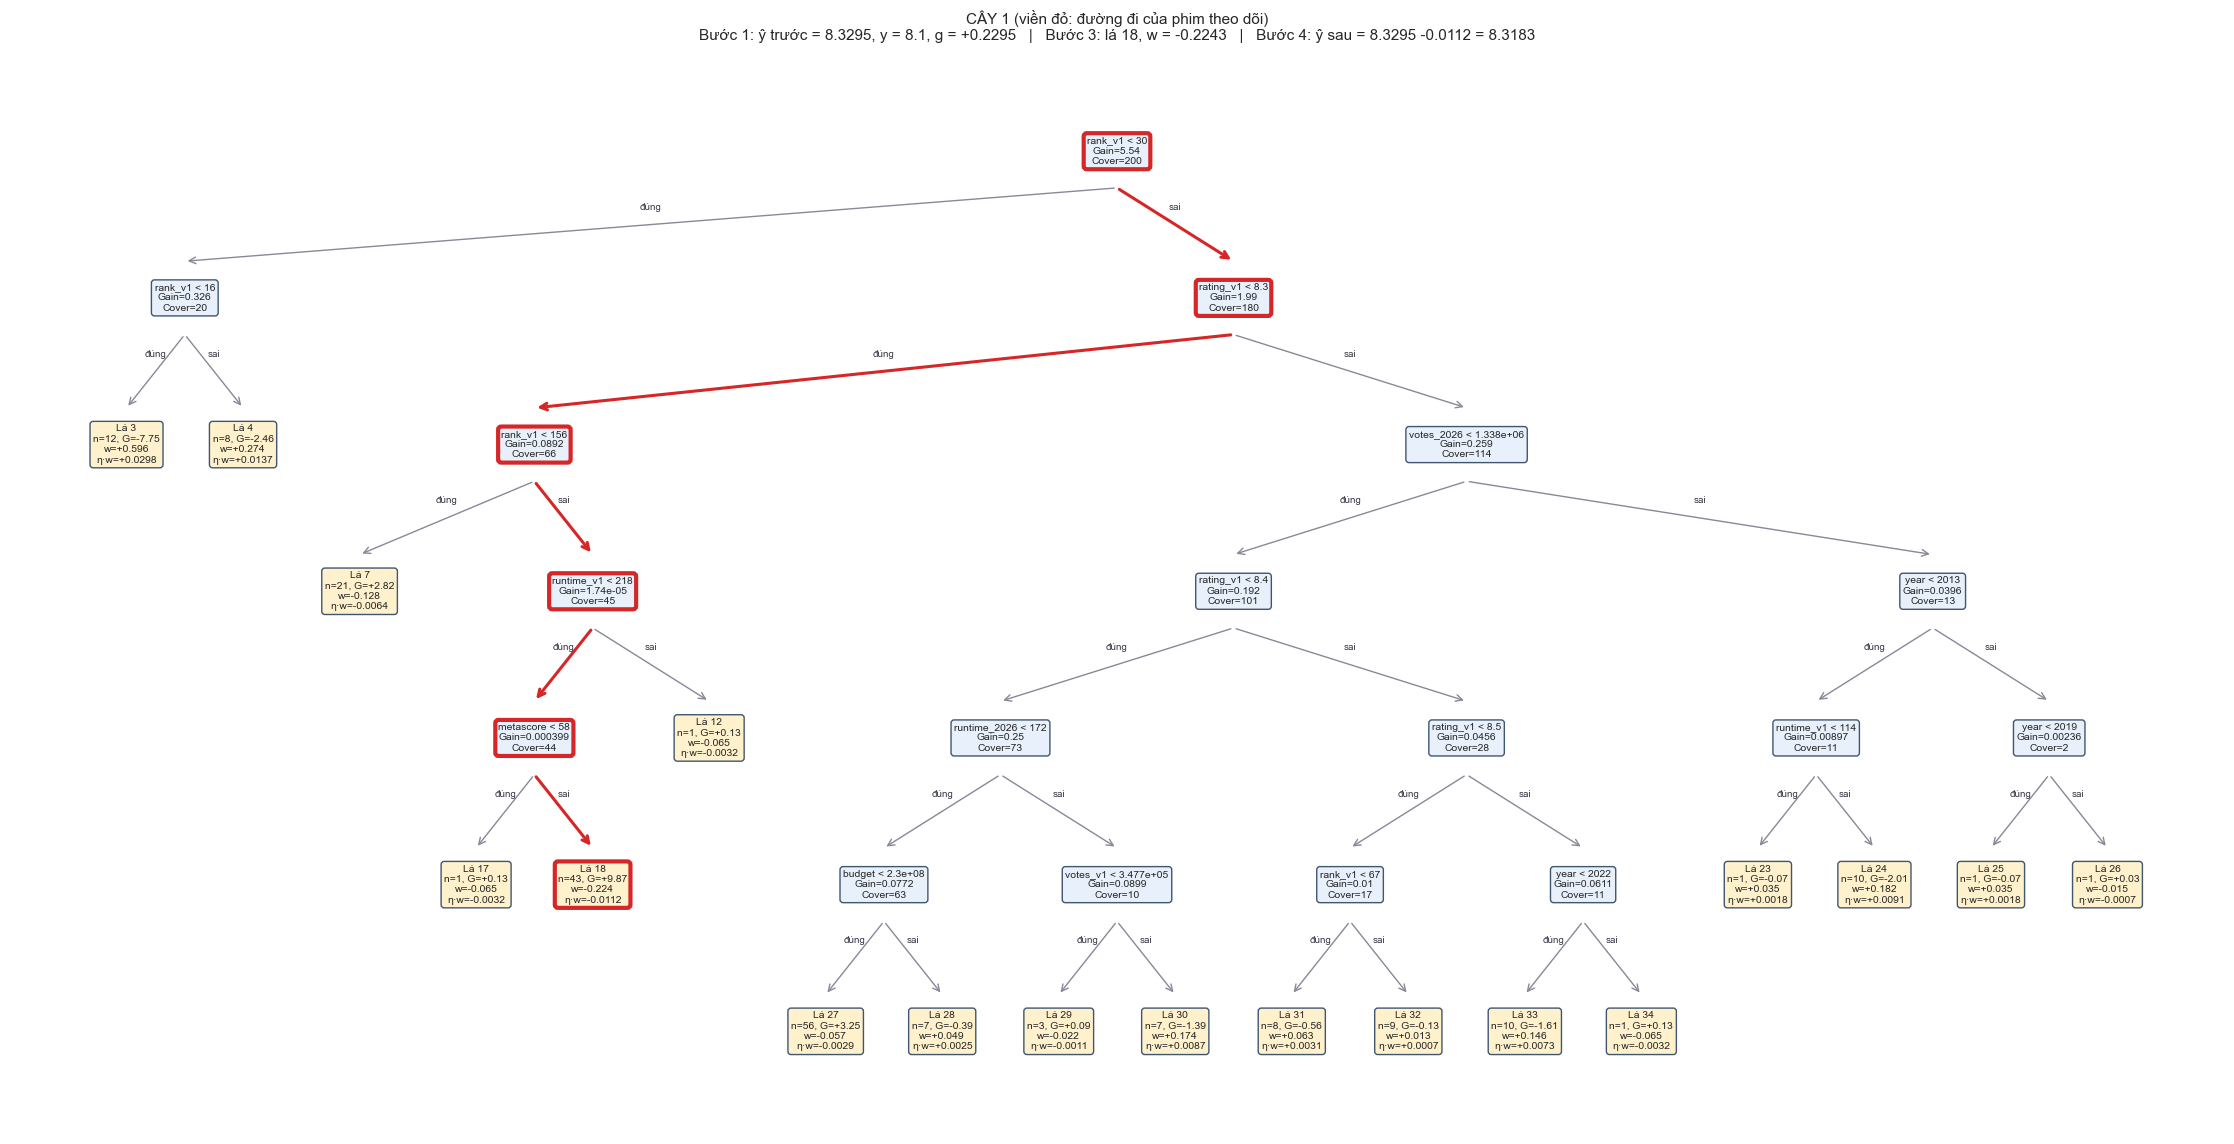

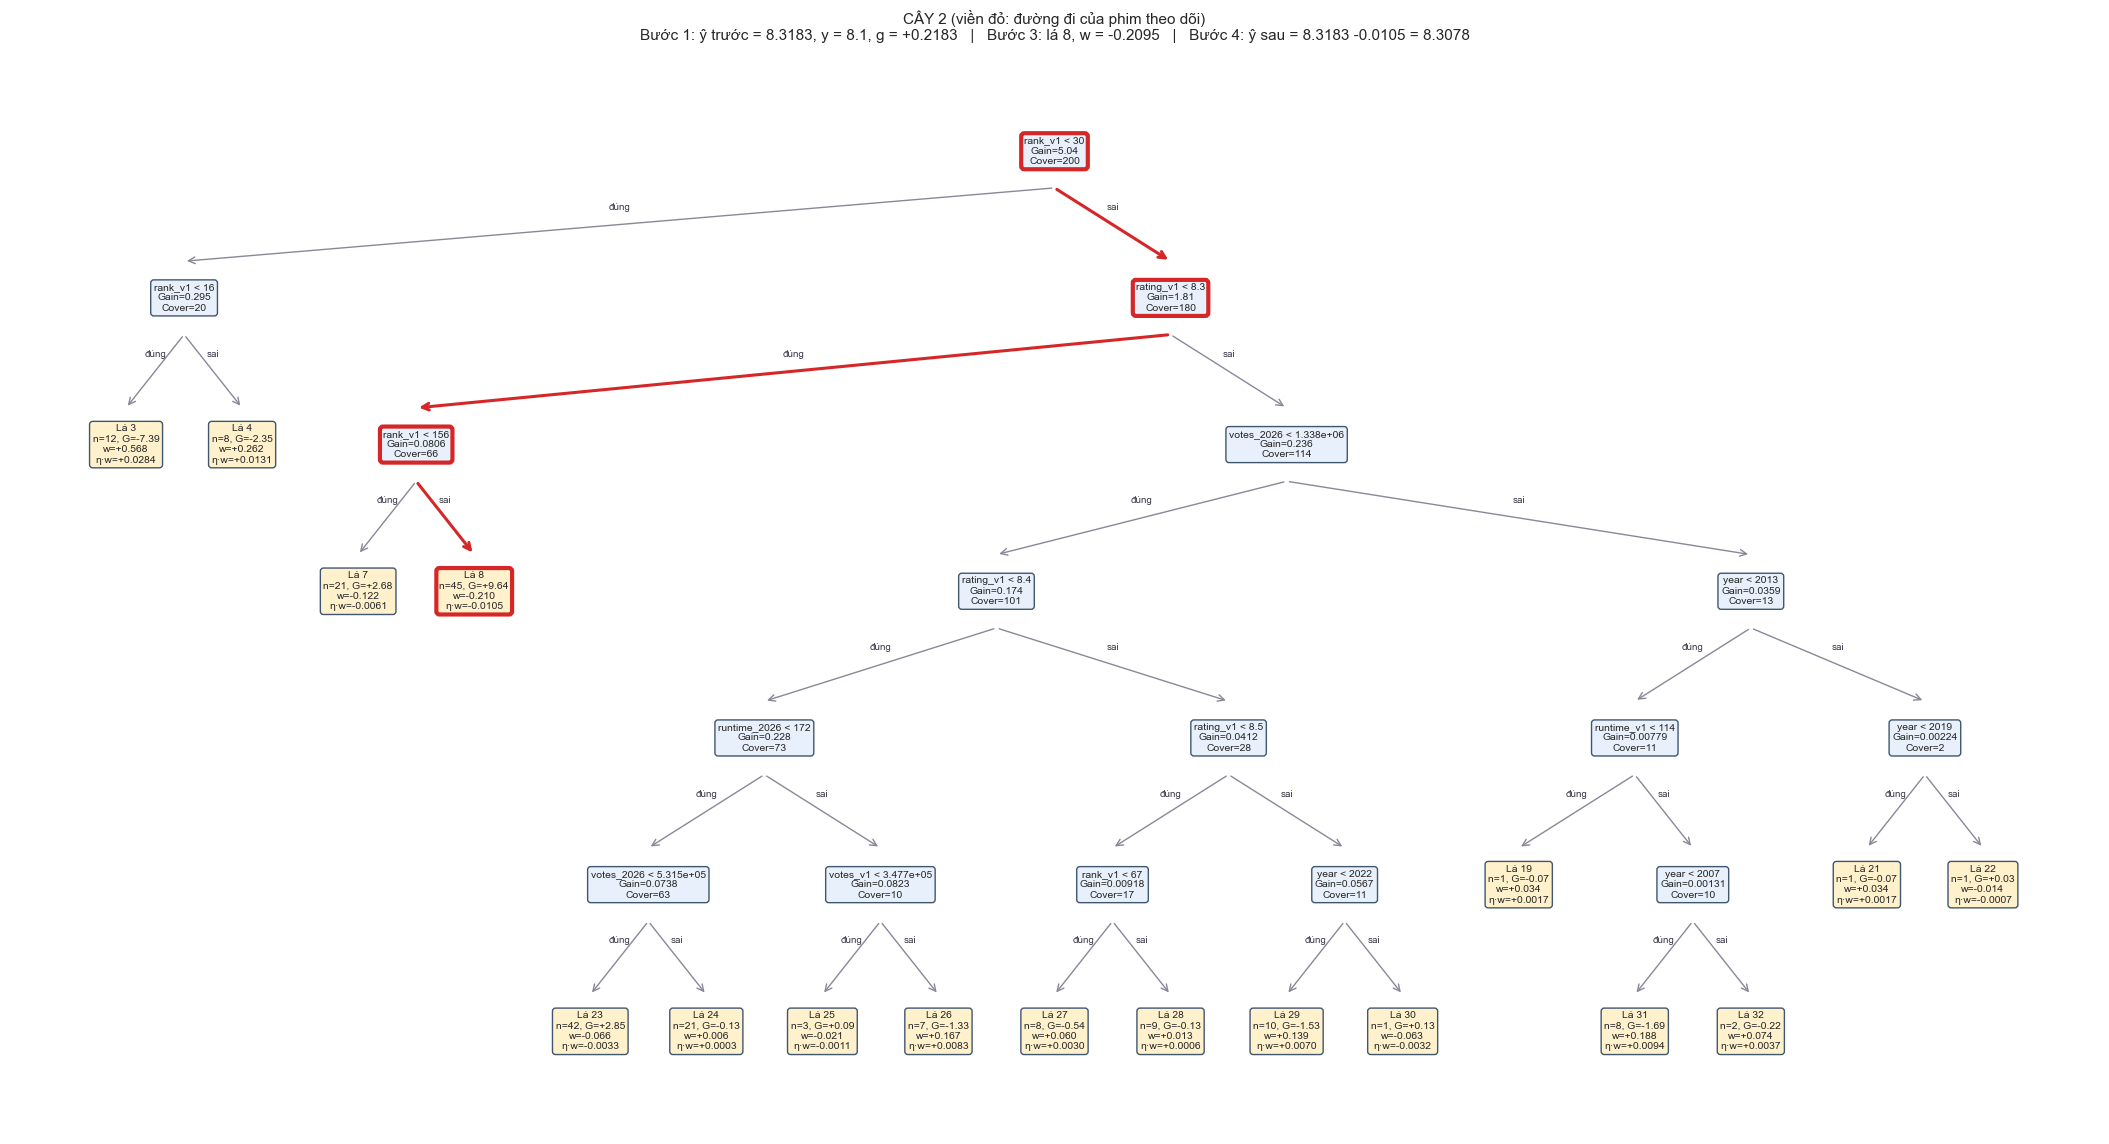

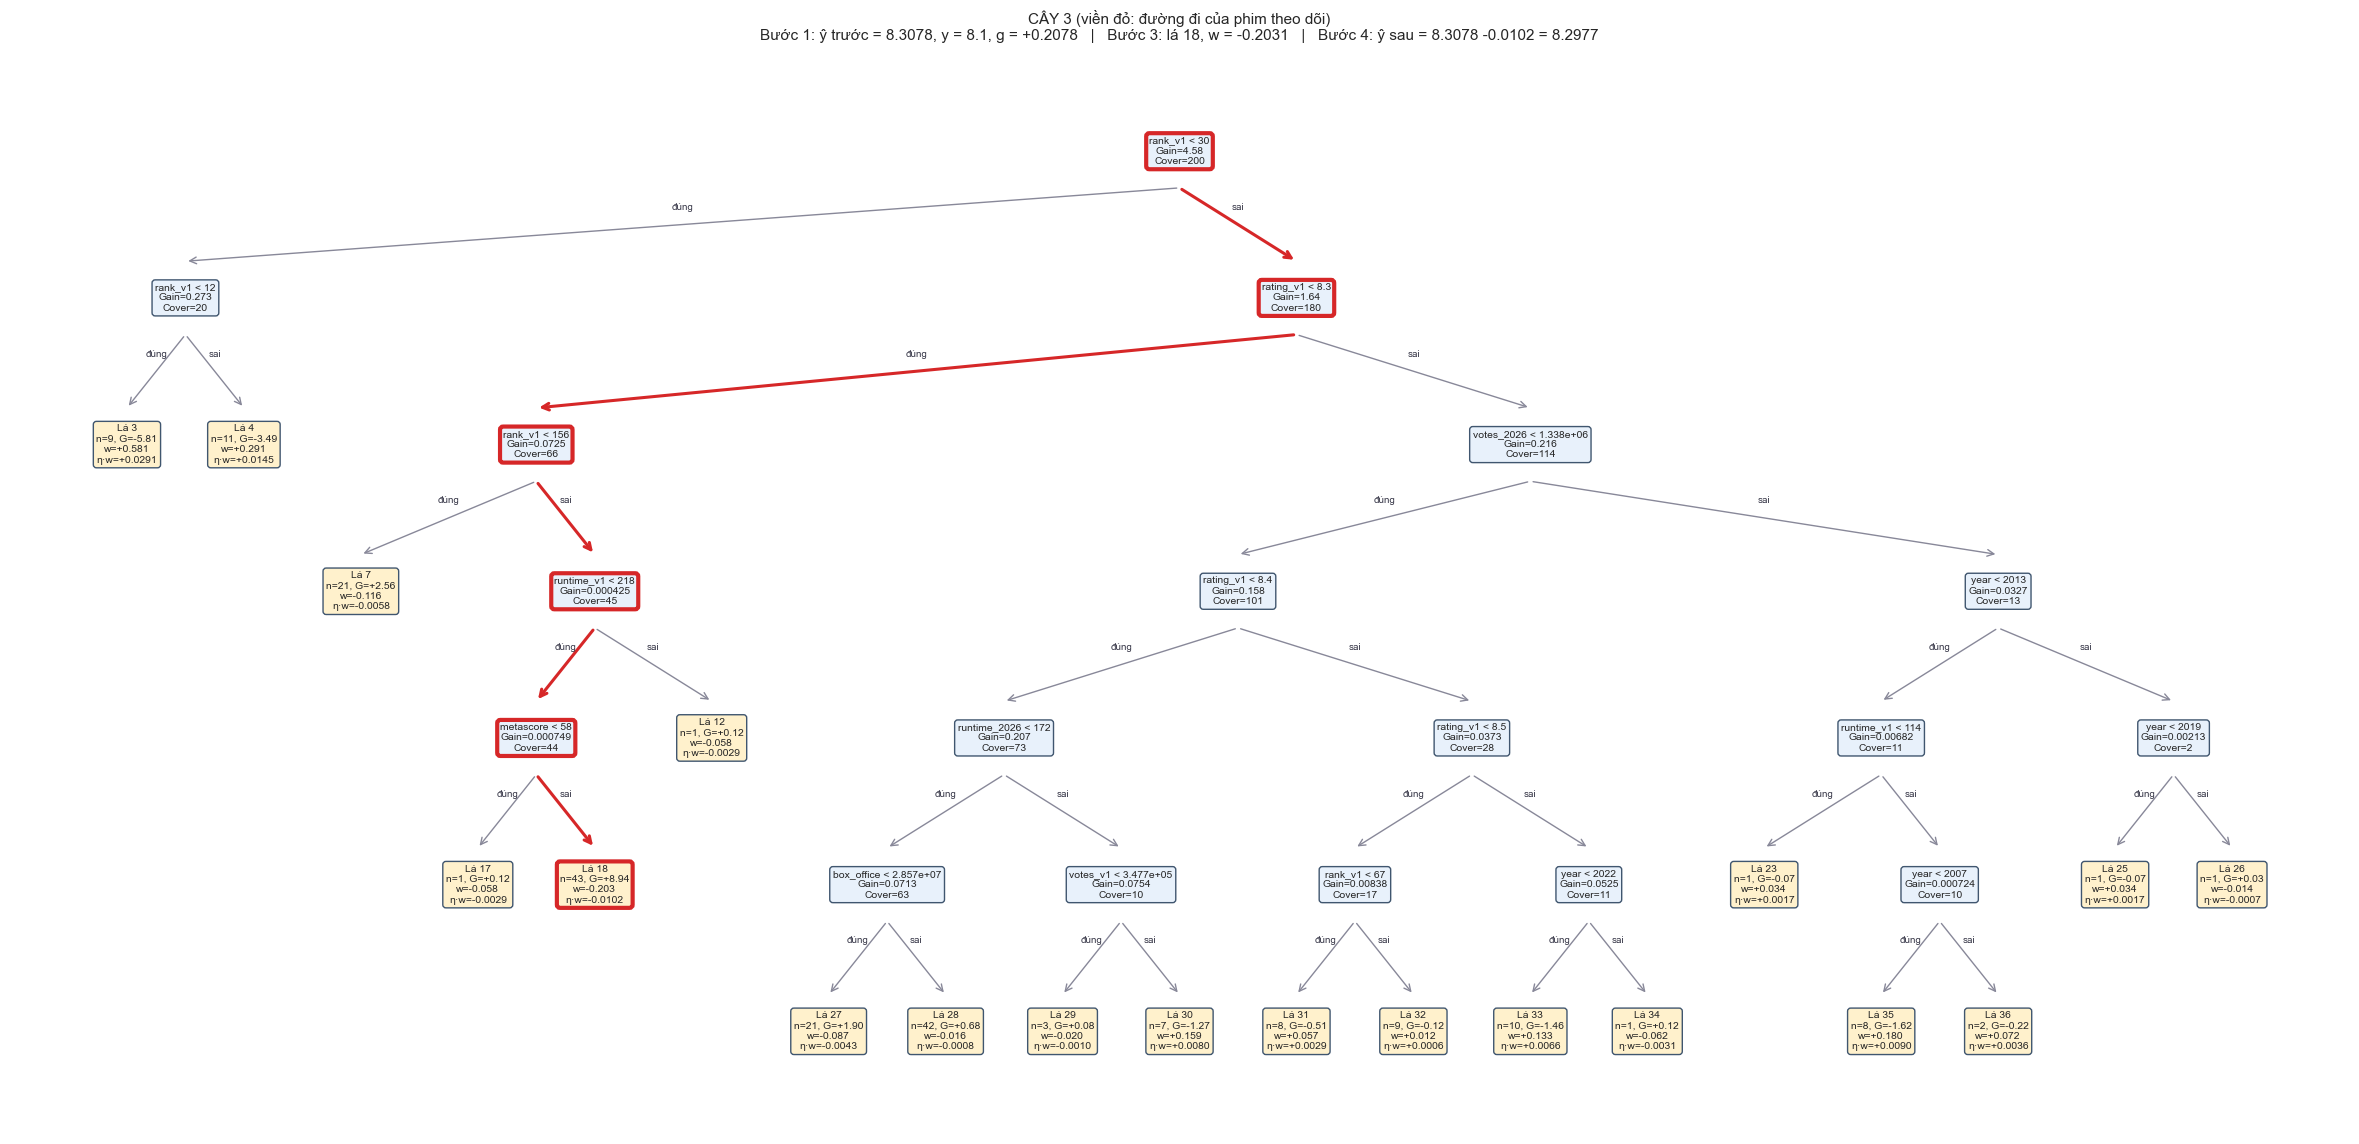

In [27]:
TREES_TO_DRAW = [1, 2, 3]          # số thứ tự các cây muốn vẽ (đếm từ 1)

def _n_leaves(node):
    return 1 if 'leaf' in node else sum(_n_leaves(c) for c in node['children'])

def _depth(node):
    return 0 if 'leaf' in node else 1 + max(_depth(c) for c in node['children'])

def _path_to_leaf(node, target_id, path=()):
    path = path + (node['nodeid'],)
    if 'leaf' in node:
        return path if node['nodeid'] == target_id else None
    for c in node['children']:
        found = _path_to_leaf(c, target_id, path)
        if found:
            return found
    return None

def draw_annotated_tree(ax, node, x_left, x_right, stats, hl_ids, depth=0, parent=None, edge_label=None):
    x, yy = (x_left + x_right) / 2, -depth
    on_path = node['nodeid'] in hl_ids
    if 'leaf' in node:
        n, G_, w_, eta_w = stats[node['nodeid']]
        label = f"Lá {node['nodeid']}\nn={n}, G={G_:+.2f}\nw={w_:+.3f}\nη·w={eta_w:+.4f}"
        fc = '#fff1cc'
    else:
        label = f"{node['split']} < {float(node['split_condition']):.4g}\nGain={float(node.get('gain', 0)):.3g}\nCover={float(node.get('cover', 0)):.0f}"
        fc = '#e8f1fb'
    ax.text(x, yy, label, ha='center', va='center', fontsize=7.5,
            bbox=dict(boxstyle='round,pad=0.3', fc=fc, ec='#d62728' if on_path else '#40566f',
                      lw=3 if on_path else 1))
    if parent is not None:
        ax.annotate('', xy=(x, yy + 0.25), xytext=(parent[0], parent[1] - 0.25),
                    arrowprops=dict(arrowstyle='->', color='#d62728' if on_path else '#889', lw=2.2 if on_path else 1))
        ax.text((x + parent[0]) / 2, (yy + parent[1]) / 2 + 0.1, edge_label, ha='center', fontsize=7, color='#334')
    if 'leaf' not in node:
        kids = {c['nodeid']: c for c in node['children']}
        left, right = kids[node['yes']], kids[node['no']]
        lw, rw = _n_leaves(left), _n_leaves(right)
        mid = x_left + (x_right - x_left) * lw / (lw + rw)
        draw_xgb_child = draw_annotated_tree
        draw_xgb_child(ax, left, x_left, mid, stats, hl_ids, depth + 1, (x, yy), 'đúng')
        draw_xgb_child(ax, right, mid, x_right, stats, hl_ids, depth + 1, (x, yy), 'sai')

for k in [t_ - 1 for t_ in TREES_TO_DRAW]:
    tree = dumps[k]
    g_k = pred_before_train[:, k] - y_tr                        # Bước 1: g tính lại từ ŷ hiện tại
    grp = pd.DataFrame({'leaf': leaf_id_train[:, k], 'g': g_k}).groupby('leaf')['g'].agg(['size', 'sum'])
    stats = {lid: (int(r_['size']), float(r_['sum']), -float(r_['sum']) / (r_['size'] + LAMBDA),
                   leaf_val[k][lid]) for lid, r_ in grp.iterrows()}   # Bước 3: w = -G/(H+λ); η·w lấy từ cây thật

    my_leaf = int(leaf_id_test[pos, k])
    hl_ids = set(_path_to_leaf(tree, my_leaf) or ())

    n_l = _n_leaves(tree)
    fig, ax = plt.subplots(figsize=(max(14, 1.25 * n_l), 2.0 + 1.6 * _depth(tree)))
    draw_annotated_tree(ax, tree, 0, n_l, stats, hl_ids)
    ax.set_xlim(-0.5, n_l + 0.5); ax.set_ylim(-_depth(tree) - 0.7, 0.7); ax.axis('off')
    ax.set_title(
        f"CÂY {k + 1} (viền đỏ: đường đi của phim theo dõi)\n"
        f"Bước 1: ŷ trước = {pred_before_test[k]:.4f}, y = {trace_y:.1f}, g = {pred_before_test[k] - trace_y:+.4f}   |   "
        f"Bước 3: lá {my_leaf}, w = {stats[my_leaf][2]:+.4f}   |   "
        f"Bước 4: ŷ sau = {pred_before_test[k]:.4f} {stats[my_leaf][3]:+.4f} = {pred_after_test[k]:.4f}",
        fontsize=11)
    plt.tight_layout(); plt.show()

#### Kiểm chứng: công thức có khớp XGBoost thật không?
Hai kiểm tra trên **toàn bộ 300 cây**: (1) mọi lá: $\eta\cdot(-G/(H+\lambda))$ bằng giá trị lá XGBoost lưu; (2) Gain tính tay tại nút gốc bằng Gain trong cây.

In [28]:
max_leaf_err, n_leaves = 0.0, 0
for k in range(N_TREES):
    g = pred_before_train[:, k] - y_tr
    grp = pd.DataFrame({'leaf': leaf_id_train[:, k], 'g': g}).groupby('leaf')['g'].agg(['sum', 'size'])
    w_all = -grp['sum'] / (grp['size'] + LAMBDA)
    dump_all = pd.Series(leaf_val[k]).reindex(grp.index)
    max_leaf_err = max(max_leaf_err, float((ETA * w_all - dump_all).abs().max()))
    n_leaves += len(grp)
print(f'1) Trọng số lá: kiểm {n_leaves} lá của {N_TREES} cây, lệch lớn nhất = {max_leaf_err:.2e}', '✓' if max_leaf_err < 1e-4 else '✗')

ok_gain = np.allclose(detail['Gain (tính tay)'], detail['Gain (cây thật)'], rtol=1e-3, atol=1e-6, equal_nan=True)
print(f'2) Gain nút gốc: công thức khớp cây thật ở cả {N_TREES} cây', '✓' if ok_gain else '✗')

1) Trọng số lá: kiểm 6748 lá của 300 cây, lệch lớn nhất = 4.22e-07 ✓
2) Gain nút gốc: công thức khớp cây thật ở cả 300 cây ✓


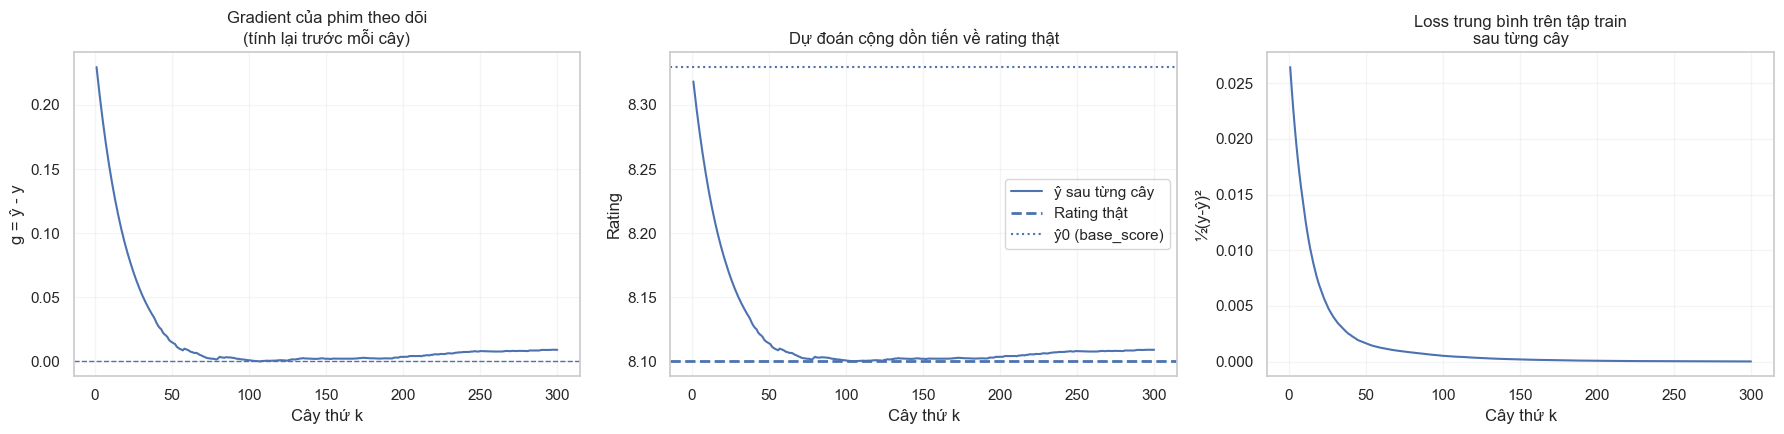

KẾT LUẬN CƠ CHẾ:
• Bước 0: ŷ(0) = trung bình rating, chưa có cây nào.
• Mỗi vòng: tính g, h từ ŷ hiện tại -> chọn split theo Gain -> w của lá = -G/(H+λ) -> nhân η.
• Cập nhật: ŷ_mới = ŷ_cũ + η·w. Sang cây kế tiếp, g được tính lại từ ŷ_mới.
• Vì vậy cây sau không học lại y từ đầu mà sửa phần sai còn lại của mô hình.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(detail['Cây'], detail['g = ŷ - y'])
axes[0].axhline(0, linestyle='--', linewidth=1)
axes[0].set_title('Gradient của phim theo dõi\n(tính lại trước mỗi cây)')
axes[0].set_xlabel('Cây thứ k'); axes[0].set_ylabel('g = ŷ - y')

axes[1].plot(detail['Cây'], detail['ŷ sau cây'], label='ŷ sau từng cây')
axes[1].axhline(trace_y, linestyle='--', linewidth=2, label='Rating thật')
axes[1].axhline(base, linestyle=':', linewidth=1.5, label='ŷ0 (base_score)')
axes[1].set_title('Dự đoán cộng dồn tiến về rating thật')
axes[1].set_xlabel('Cây thứ k'); axes[1].set_ylabel('Rating'); axes[1].legend()

axes[2].plot(detail['Cây'], detail['Loss train TB'])
axes[2].set_title('Loss trung bình trên tập train\nsau từng cây')
axes[2].set_xlabel('Cây thứ k'); axes[2].set_ylabel('½(y-ŷ)²')

for a in axes:
    a.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print('KẾT LUẬN CƠ CHẾ:')
print('• Bước 0: ŷ(0) = trung bình rating, chưa có cây nào.')
print('• Mỗi vòng: tính g, h từ ŷ hiện tại -> chọn split theo Gain -> w của lá = -G/(H+λ) -> nhân η.')
print('• Cập nhật: ŷ_mới = ŷ_cũ + η·w. Sang cây kế tiếp, g được tính lại từ ŷ_mới.')
print('• Vì vậy cây sau không học lại y từ đầu mà sửa phần sai còn lại của mô hình.')

### Phần C. Hessian thay đổi theo mẫu (bài toán phân loại)
Với loss bình phương, $h=1$ nên Hessian chưa thể hiện vai trò. Với **phân loại nhị phân** (loss logistic), gọi $p$ là xác suất đang dự đoán:
$$g_i=p_i-y_i,\qquad h_i=p_i(1-p_i)$$
$h$ lớn nhất khi $p=0.5$ (mô hình **chưa chắc**) và nhỏ khi $p$ gần 0 hoặc 1 (đã khá chắc). Hessian đi vào cả $w=-G/(H+\lambda)$ lẫn Gain.

In [30]:
lam_c = 1.0
y_c = np.array([1, 0, 1, 0, 1, 0])                      # 1 = phim được đánh giá cao
p_c = np.array([0.90, 0.85, 0.50, 0.10, 0.20, 0.50])    # xác suất mô hình đang dự đoán
g_c = p_c - y_c
h_c = p_c * (1 - p_c)

display(pd.DataFrame({'y': y_c, 'p hiện tại': p_c, 'g = p - y': g_c, 'h = p(1-p)': h_c}).round(4))
G_c, H_c = g_c.sum(), h_c.sum()
print(f'G = {G_c:.4f} | H = {H_c:.4f} | w = -G/(H+λ) = {-G_c / (H_c + lam_c):.4f}')
print('Loss bình phương: h luôn = 1. Logloss: mẫu "chưa chắc" (p≈0.5) có h lớn, mẫu "đã chắc" có h nhỏ.')

,y,p hiện tại,g = p - y,h = p(1-p)
0,1,0.90,-0.10,0.0900
1,0,0.85,0.85,0.1275
2,1,0.50,-0.50,0.2500
3,0,0.10,0.10,0.0900
4,1,0.20,-0.80,0.1600
5,0,0.50,0.50,0.2500


G = 0.0500 | H = 0.9675 | w = -G/(H+λ) = -0.0254
Loss bình phương: h luôn = 1. Logloss: mẫu "chưa chắc" (p≈0.5) có h lớn, mẫu "đã chắc" có h nhỏ.


## Biểu đồ 3. MAE – RMSE – R²
Cùng tập test, dự đoán từ đủ 300 cây mỗi mô hình. MAE/RMSE thấp hơn và R² cao hơn là tốt hơn.

,Mô hình,MAE,RMSE,R²
0,Random Forest (300 cây),0.0675,0.1117,0.6617
1,XGBoost (300 cây),0.0628,0.1054,0.6988


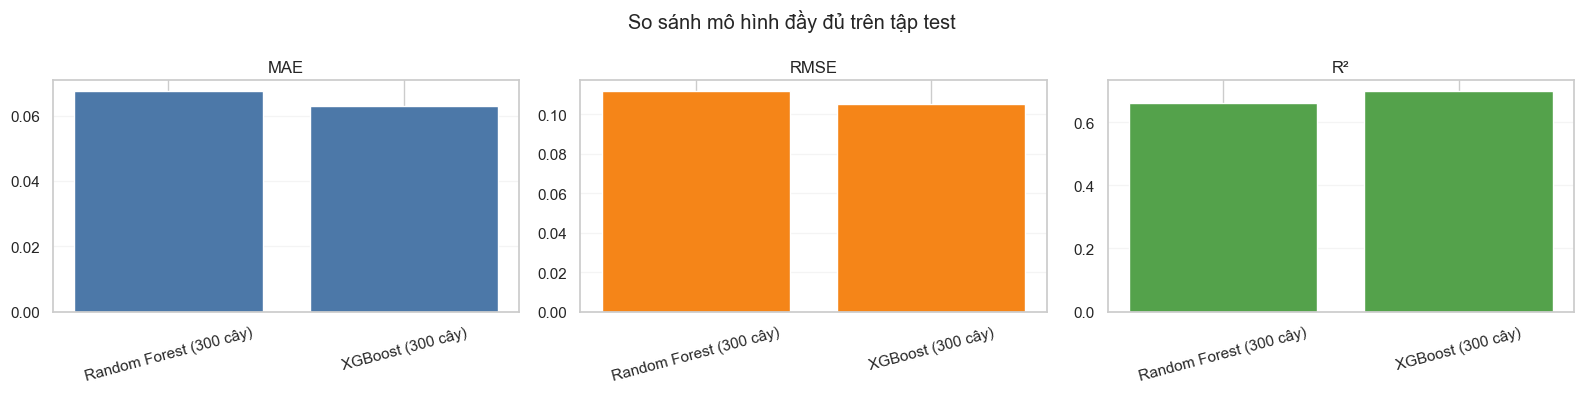

In [31]:
full_metrics = pd.DataFrame([
    {'Mô hình': 'Random Forest (300 cây)', 'MAE': mean_absolute_error(y_test, rf_full_pred),
     'RMSE': np.sqrt(mean_squared_error(y_test, rf_full_pred)), 'R²': r2_score(y_test, rf_full_pred)},
    {'Mô hình': 'XGBoost (300 cây)', 'MAE': mean_absolute_error(y_test, xgb_full_pred),
     'RMSE': np.sqrt(mean_squared_error(y_test, xgb_full_pred)), 'R²': r2_score(y_test, xgb_full_pred)},
])
display(full_metrics.round(4))
# vẽ 3 biểu đồ để so sánh
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, color in zip(axes, ['MAE', 'RMSE', 'R²'], ['#4C78A8', '#F58518', '#54A24B']):
    ax.bar(full_metrics['Mô hình'], full_metrics[metric], color=color)
    ax.set_title(metric); ax.tick_params(axis='x', rotation=15); ax.grid(axis='y', alpha=0.2)
fig.suptitle('So sánh mô hình đầy đủ trên tập test')
plt.tight_layout(); plt.show()

**Lưu ý khi kết luận:** tập test chỉ có 50 phim và chỉ chia một lần, nên chênh lệch nhỏ giữa hai mô hình chưa đủ để khẳng định mô hình nào luôn tốt hơn.

## Biểu đồ 4. Thời gian huấn luyện
Thời gian fit đã đo ở mục 4. Giá trị trung bình mỗi cây là `tổng thời gian / 300`. RF xây các cây **song song** (`n_jobs=-1`), XGBoost xây **tuần tự** nên con số/cây chỉ là chỉ báo tổng quát.

,Mô hình,Fit toàn bộ 300 cây (giây),Trung bình / cây (giây)
0,Random Forest,1.289895,0.004300
1,XGBoost hist,1.796575,0.005989


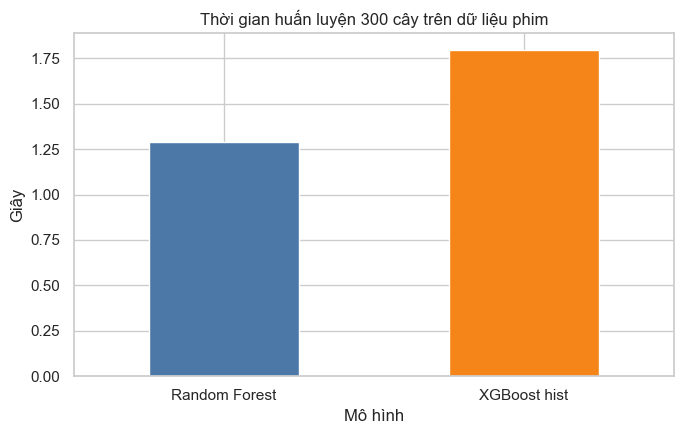

In [32]:
# so sánh thời gian huấn luyện 300 cây của Random Forest và XGBoost hist
# tạo bảng thời gian huấn luyện
full_times = pd.DataFrame([
    {'Mô hình': 'Random Forest', 'Fit toàn bộ 300 cây (giây)': rf_full_seconds, 'Trung bình / cây (giây)': rf_full_seconds / N_TREES},
    {'Mô hình': 'XGBoost hist',  'Fit toàn bộ 300 cây (giây)': xgb_full_seconds, 'Trung bình / cây (giây)': xgb_full_seconds / N_TREES},
])
display(full_times.round(6))

# vẽ biểu đồ so sánh thời gian
full_times.set_index('Mô hình')['Fit toàn bộ 300 cây (giây)'].plot(kind='bar', color=['#4C78A8', '#F58518'], figsize=(7, 4.5))
plt.title('Thời gian huấn luyện 300 cây trên dữ liệu phim'); plt.ylabel('Giây'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Lưu ý:** dữ liệu chỉ có 200 dòng, nên chênh lệch phần lớn do chi phí khởi tạo. Kết quả phụ thuộc máy và phiên bản thư viện, và chỉ có ý nghĩa so sánh trong cùng một lần chạy.

## Biểu đồ 5. Actual vs Predicted
Mỗi chấm là một phim test; đường chéo là dự đoán hoàn hảo.

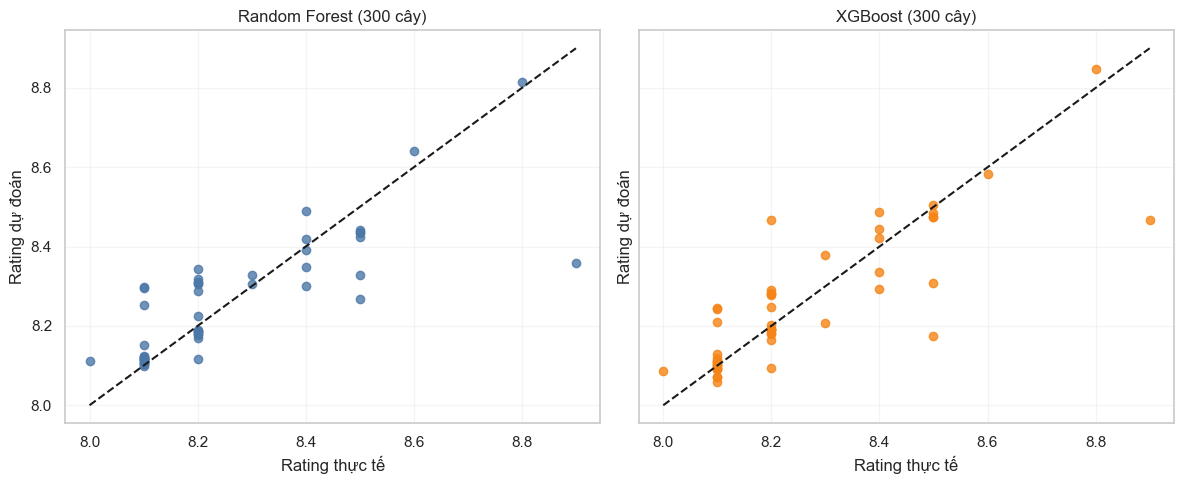

,Phim,Rating thực tế,RF dự đoán,XGB dự đoán,Sai số RF,Sai số XGB
188,Ratatouille,8.1,8.1176,8.1107,-0.0176,-0.0107
6,A Beautiful Mind,8.2,8.1876,8.1822,0.0124,0.0178
125,Klaus,8.2,8.1161,8.0927,0.0839,0.1073
75,Forrest Gump,8.8,8.8151,8.8482,-0.0151,-0.0482
150,Metropolis,8.2,8.2880,8.2799,-0.0880,-0.0799
241,The Deer Hunter,8.1,8.1238,8.0992,-0.0238,0.0008
260,The Incredibles,8.0,8.1106,8.0875,-0.1106,-0.0875
245,The Exorcist,8.1,8.1045,8.0587,-0.0045,0.0413
9,A Silent Voice: The Movie,8.2,8.3090,8.2896,-0.1090,-0.0896
140,Logan,8.1,8.1157,8.0918,-0.0157,0.0082


Các phim sai số lớn nhất (theo XGBoost):


,Phim,Rating thực tế,RF dự đoán,XGB dự đoán,Sai số RF,Sai số XGB
21,Attack on Titan: The Last Attack,8.9,8.3596,8.4665,0.5404,0.4335
85,Grave of the Fireflies,8.5,8.2675,8.1751,0.2325,0.3249
19,Amélie,8.2,8.3430,8.4661,-0.1430,-0.2661
213,Spider-Man: Across the Spider-Verse,8.5,8.3296,8.3082,0.1704,0.1918
232,The Battle of Algiers,8.1,8.2985,8.2462,-0.1985,-0.1462


In [33]:
# Vẽ biểu đồ so sánh Rating thực tế và Rating dự đoán
# Tạo bảng dự đoán cho từng bộ phim, tính sai số của mỗi mô hình và tìm 5 phim mà XGBoost dự đoán sai nhiều nhất
actual = y_test.to_numpy()
lo = min(actual.min(), rf_full_pred.min(), xgb_full_pred.min())
hi = max(actual.max(), rf_full_pred.max(), xgb_full_pred.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (title, pred, color) in zip(axes, [('Random Forest (300 cây)', rf_full_pred, '#4C78A8'),
                                            ('XGBoost (300 cây)', xgb_full_pred, '#F58518')]):
    ax.scatter(actual, pred, alpha=0.8, color=color)
    ax.plot([lo, hi], [lo, hi], 'k--')
    ax.set_title(title); ax.set_xlabel('Rating thực tế'); ax.set_ylabel('Rating dự đoán'); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

pred_table = pd.DataFrame({'Phim': df_model.loc[y_test.index, 'movie_name'],
                           'Rating thực tế': y_test,
                           'RF dự đoán': rf_full_pred, 'XGB dự đoán': xgb_full_pred}, index=y_test.index)
pred_table['Sai số RF'] = pred_table['Rating thực tế'] - pred_table['RF dự đoán']
pred_table['Sai số XGB'] = pred_table['Rating thực tế'] - pred_table['XGB dự đoán']
display(pred_table.head(15).round(4))

print('Các phim sai số lớn nhất (theo XGBoost):')
display(pred_table.reindex(pred_table['Sai số XGB'].abs().sort_values(ascending=False).index).head(5).round(4))

## Biểu đồ 6. Feature Importance
Tầm quan trọng chuẩn hóa riêng theo từng mô hình, và **không thể hiện quan hệ nhân quả**. RF dùng impurity-based importance; XGBoost (scikit-learn API) mặc định dùng gain, nên không nên so độ lớn tuyệt đối giữa hai cột.

,Random Forest,XGBoost,Thứ hạng TB
Feature,,,
rank_v1,0.3309,0.1940,1.5
rating_v1,0.2912,0.6902,1.5
votes_2026,0.1324,0.0346,3.0
runtime_2026,0.0407,0.0232,4.5
votes_v1,0.0956,0.0103,5.5
year,0.0184,0.0123,7.0
metascore,0.0200,0.0103,8.0
runtime_v1,0.0228,0.0070,8.0
budget,0.0177,0.0118,8.0


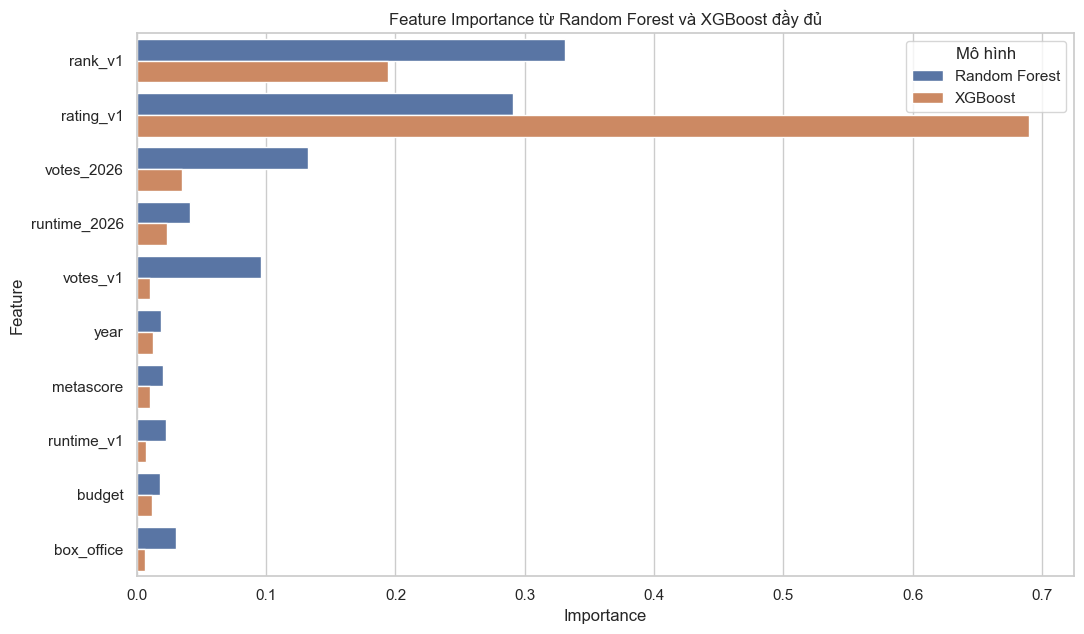

In [34]:
imp = pd.DataFrame({'Feature': FEATURES,
                    'Random Forest': rf_full.feature_importances_,
                    'XGBoost': xgb_full.feature_importances_}).set_index('Feature')
# Xếp hạng và tính thứ hạng trung bình
imp['Thứ hạng TB'] = imp[['Random Forest', 'XGBoost']].rank(ascending=False).mean(axis=1)
imp = imp.sort_values('Thứ hạng TB')
display(imp.round(4))

long = imp.drop(columns='Thứ hạng TB').reset_index().melt(id_vars='Feature', var_name='Mô hình', value_name='Importance')
plt.figure(figsize=(11, 6.5))
sns.barplot(data=long, x='Importance', y='Feature', hue='Mô hình', order=imp.index)
plt.title('Feature Importance từ Random Forest và XGBoost đầy đủ')
plt.tight_layout(); plt.show()

## Kết luận
- **Cơ chế:** RF = trung bình các cây độc lập, lá là rating. XGBoost = tổng các cây nối tiếp, lá là mức điều chỉnh $\eta\cdot w$ với $w=-G/(H+\lambda)$; $g,h$ được tính lại sau mỗi cây.
- **Kết quả:** so sánh MAE/RMSE/R² ở Biểu đồ 3 trên cùng dữ liệu và cùng cấu hình (xem hạn chế về tập test nhỏ).
- **Thuộc tính quan trọng:** `rating_v1` và `rank_v1` chi phối, phù hợp với EDA.
- **Hạn chế:** tập test nhỏ (50 phim); một số phim mới thiếu `rating_v1`, `rank_v1` nên bị điền median; bài toán thực chất là dự đoán độ trôi nhỏ quanh `rating_v1`.

# 6. Phụ lục (chỉ mở khi được hỏi)

### P1. Ba cách tìm điểm chia của XGBoost: `exact`, `approx`, `hist`
`exact` xét mọi ngưỡng chính xác; `approx` dùng ngưỡng xấp xỉ; `hist` gom giá trị vào bins. Trên dữ liệu nhỏ, chênh lệch thời gian không đáng kể và không có ý nghĩa khái quát.

In [35]:
# đo thời gian huấn luyện 3 cây trên cùng tập dữ liệu phim
res = []
for method in ['exact', 'approx', 'hist']:
    try:
        m = XGBRegressor(n_estimators=3, max_depth=2, learning_rate=0.30, objective='reg:squarederror',
                         reg_lambda=1.0, tree_method=method, random_state=SEED, n_jobs=1)
        t0 = time.perf_counter(); m.fit(X_train, y_train)
        res.append({'tree_method': method, 'Thời gian fit 3 cây (giây)': time.perf_counter() - t0, 'Trạng thái': 'OK'})
    except Exception as e:
        res.append({'tree_method': method, 'Thời gian fit 3 cây (giây)': np.nan, 'Trạng thái': f'Lỗi: {str(e)[:120]}'})
display(pd.DataFrame(res).round(6))

,tree_method,Thời gian fit 3 cây (giây),Trạng thái
0,exact,0.077207,OK
1,approx,0.054447,OK
2,hist,0.065145,OK


### P2. XGBoost xử lý giá trị thiếu (NaN) trực tiếp
Khi chia một nút, XGBoost học **hướng mặc định** (trái hoặc phải) cho các mẫu bị thiếu sao cho Gain tốt hơn, rồi lưu hướng đó trong cây. Ở đây ta fit trên `X_train_raw` (còn NaN, chưa điền median).

In [36]:
xgb_nan = XGBRegressor(n_estimators=3, max_depth=2, learning_rate=0.30, objective='reg:squarederror',
                       tree_method='hist', random_state=SEED, n_jobs=1)
xgb_nan.fit(X_train_raw, y_train)
print('Số NaN trong X_train_raw:', int(X_train_raw.isna().sum().sum()))
display(pd.DataFrame({'Rating thật': y_test.iloc[:5].to_numpy(),
                      'XGBoost (đầu vào có NaN)': xgb_nan.predict(X_test_raw)[:5]}).round(3))
print('Hướng mặc định cho NaN nằm trong trường "missing" của từng nút trong dump:')
print(xgb_nan.get_booster().get_dump(with_stats=True)[0])

Số NaN trong X_train_raw: 274


,Rating thật,XGBoost (đầu vào có NaN)
0,8.1,8.199
1,8.2,8.236
2,8.2,8.199
3,8.8,8.669
4,8.2,8.301


Hướng mặc định cho NaN nằm trong trường "missing" của từng nút trong dump:
0:[rank_v1<30] yes=1,no=2,missing=2,gain=5.53993988,cover=200
	1:[rank_v1<16] yes=3,no=4,missing=4,gain=0.326007366,cover=20
		3:leaf=0.178753823,cover=12
		4:leaf=0.0821333304,cover=8
	2:[rating_v1<8.30000019] yes=5,no=6,missing=6,gain=1.99106598,cover=180
		5:leaf=-0.0579716489,cover=66
		6:leaf=0.00713993935,cover=114



### P3. Khi dữ liệu lớn, nhiễu hoặc có ngoại lệ
- **Dữ liệu lớn:** thời gian và bộ nhớ tăng theo số dòng, số thuộc tính, số cây, độ sâu. Có thể dùng `hist`, giảm `max_depth`/`max_bin`, `subsample`/`colsample_bytree` < 1, hoặc early stopping.
- **Nhiễu/ngoại lệ:** XGBoost không tự biết điểm nào là nhiễu. Hạn chế bằng cây nông, learning rate thấp, regularization L1/L2, `gamma`, lấy mẫu hàng/cột. Cơ chế hướng mặc định chỉ dành cho NaN, không xử lý giá trị bất thường.